In [1]:
import sys
import os
import random
import time
from pathlib import Path

import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pytorch_lightning as pl

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [3]:
from img_generation.models.pixel_cnn import train_pixel_cnn
from img_generation.models.vae import VQVAE, NUM_EMBEDDINGS
from img_generation.utils import show_imgs
from img_generation.datasets import Config, DatasetType, load_dataloaders, VAE_TRANSFORM_MONO

In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [5]:
config = Config(dataset_type=DatasetType.FASHION_MNIST, data_dir="../data/fashion_mnist", model_type="vae", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config, transform=VAE_TRANSFORM_MONO)

print(f"All classes: {classes}")
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 54000 images, 10 classes.
All classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Number of all classes: 10


In [6]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [7]:
model_path = "../pretrained_models/vae"
hidden_dim = 32
num_embeddings = NUM_EMBEDDINGS
# ^^Number of vectors in the codebook

vq_vae = VQVAE(in_channels=input_channels, hidden_dim=hidden_dim, num_embeddings=num_embeddings)
vq_vae.load_state_dict(torch.load(f=os.path.join(model_path, "vq_vae.pth"), weights_only=True))
vq_vae.to(device)

VQVAE(
  (encoder): ConvBlock(
    (conv_layers): Sequential(
      (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): SiLU()
      (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (4): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    )
  )
  (vq_layer): VQEmbedding(
    (embedding): Embedding(1024, 64)
  )
  (decoder): DeconvBlock(
    (de_conv): Sequential(
      (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): SiLU()
      (3): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    )
  )
  (normalize): Sigmoid()
)

In [8]:
vq_vae.eval()

tokenized_dataloaders = {}

with torch.inference_mode():
    for phase in ["train", "val", "test"]:
        all_tokens = []
        for imgs, labels in dataloaders[phase]:
            imgs = imgs.to(device)
            z_q, vq_loss, encoding_indices = vq_vae.encode(imgs) # encoding_indices.shape = (b * h * w)
            b, c, h, w = z_q.shape
            tokens_2d = encoding_indices.view(b, h, w)  # from batch of inline tensor of pixel-tokens [0..8x8] to tensor-matrix of pixel-tokens [8, 8]
            all_tokens.append(tokens_2d.cpu())
        
        final_tokens = torch.cat(all_tokens, dim=0).long()
        final_tokens = final_tokens.unsqueeze(1)
        token_dataset = TensorDataset(final_tokens, final_tokens)
        
        is_train = (phase == "train")
        tokenized_dataloaders[phase] = DataLoader(
            token_dataset,
            batch_size=config.batch_size,
            shuffle=is_train,
            drop_last=is_train,
            pin_memory=True,
            num_workers=config.num_workers
        ) 

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv_vstack │ VerticalStackConvolution   │    640 │ train │     0 │
│ 1 │ conv_hstack │ HorizontalStackConvolution │    256 │ train │     0 │
│ 2 │ conv_layers │ ModuleList                 │  834 K │ train │     0 │
│ 3 │ conv_out    │ Conv2d                     │ 66.6 K │ train │     0 │
└───┴─────────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 902 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 902 K                                                                                                
Total estimated model params size (MB): 3.608                                                                      
Modules in train mode: 55                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'val_dataloader' to speed up the dataloader worker initialization.


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


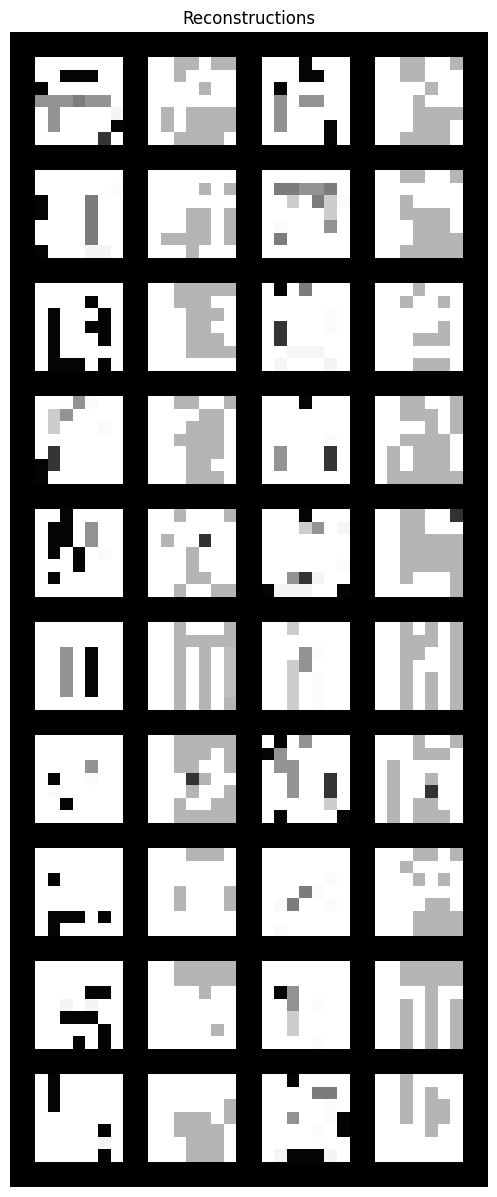

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader worker initialization.


Epoch 0: 100%|██████████| 421/421 [00:16<00:00, 26.31it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


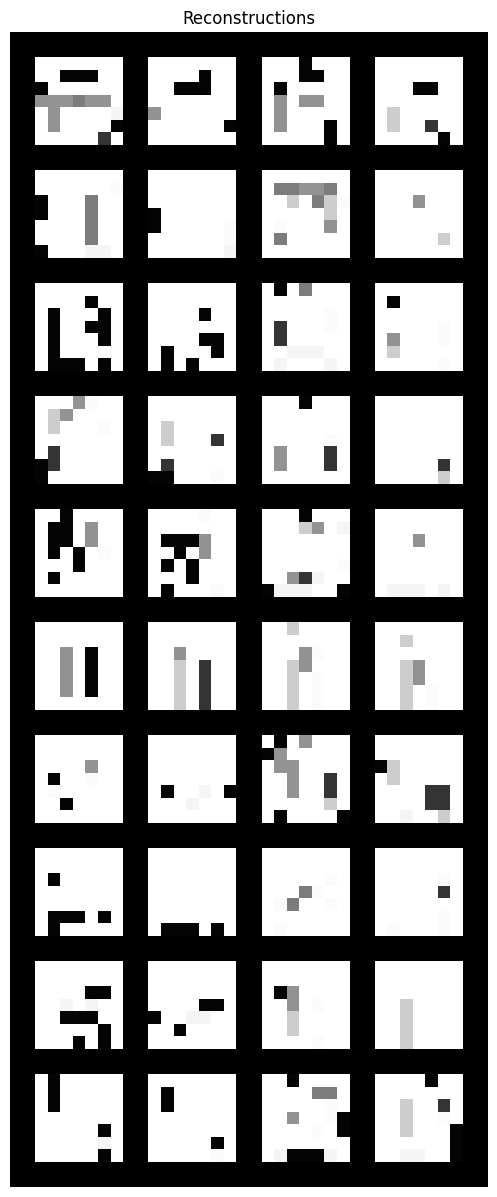

Epoch 1: 100%|██████████| 421/421 [00:15<00:00, 26.38it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


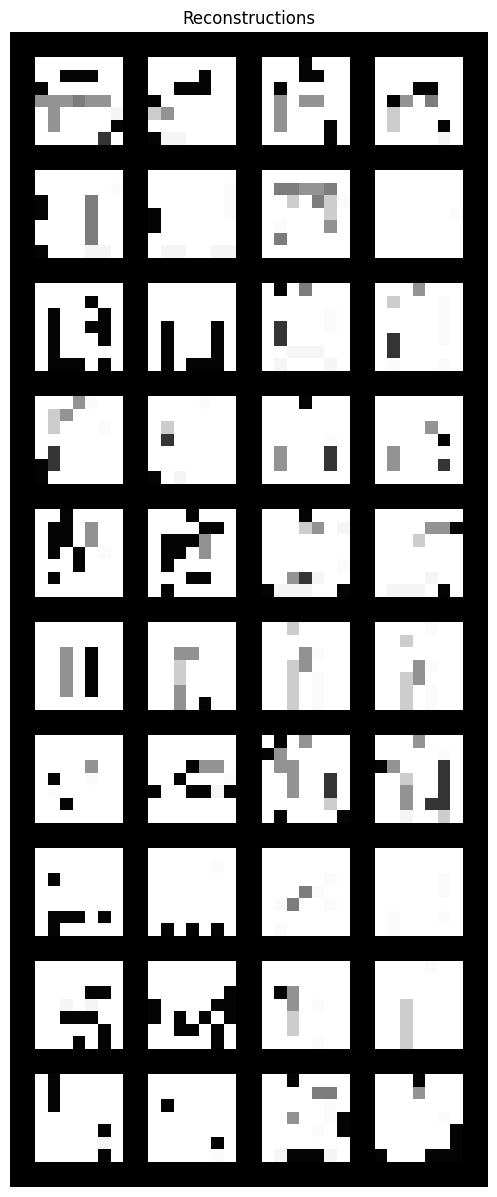

Epoch 2: 100%|██████████| 421/421 [00:14<00:00, 28.77it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


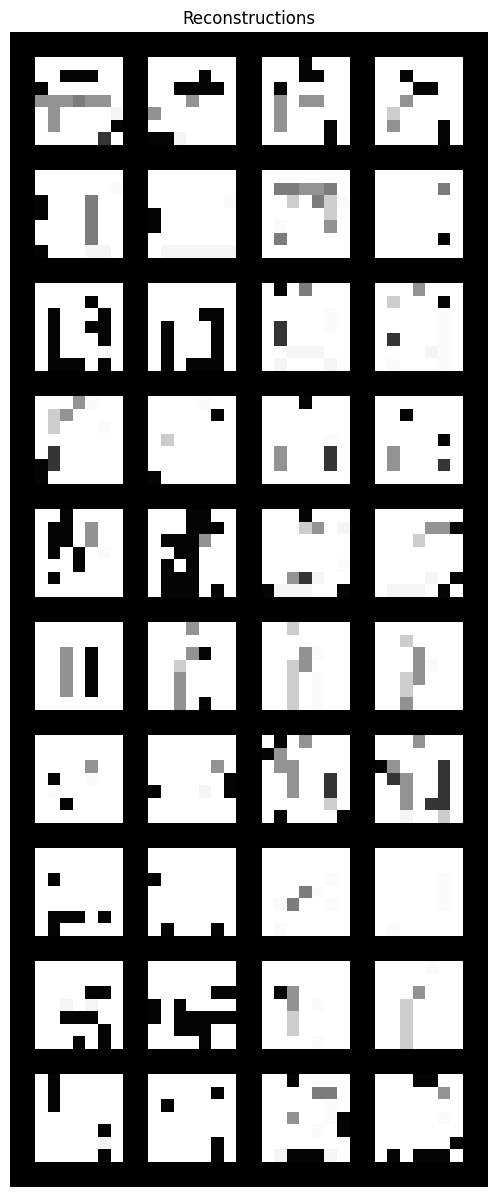

Epoch 3: 100%|██████████| 421/421 [00:14<00:00, 28.83it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


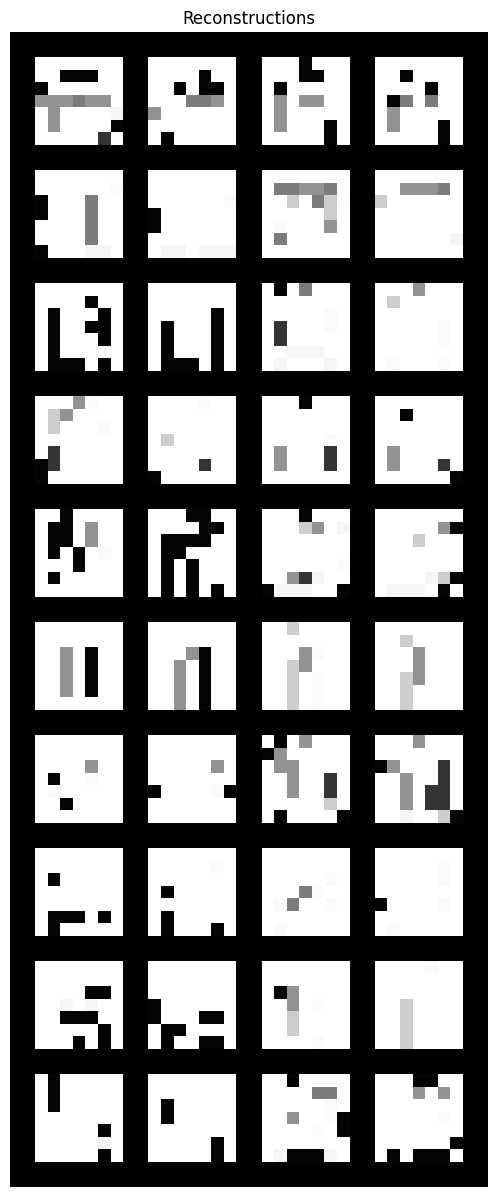

Epoch 4: 100%|██████████| 421/421 [00:14<00:00, 28.86it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


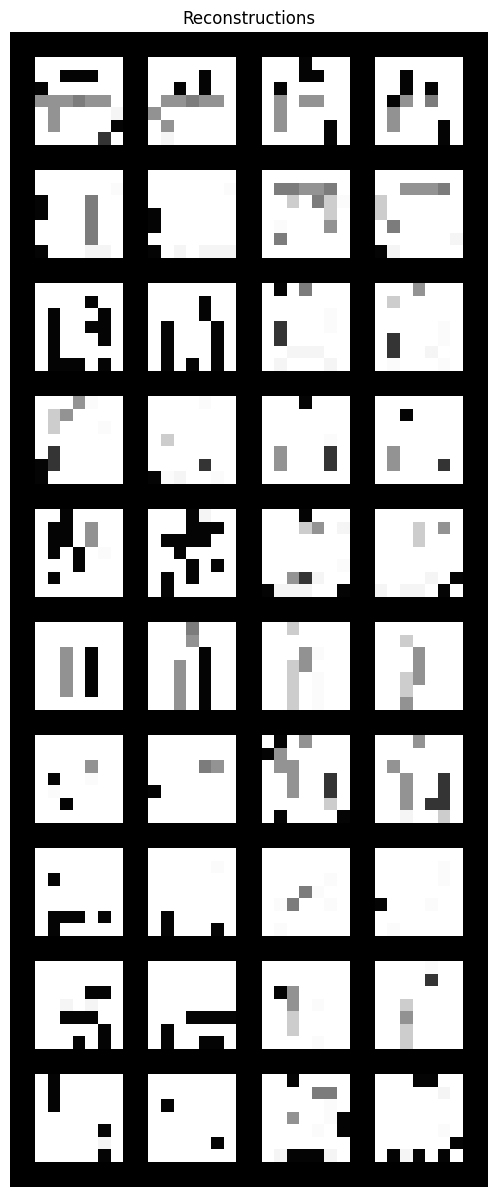

Epoch 5: 100%|██████████| 421/421 [00:14<00:00, 28.86it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


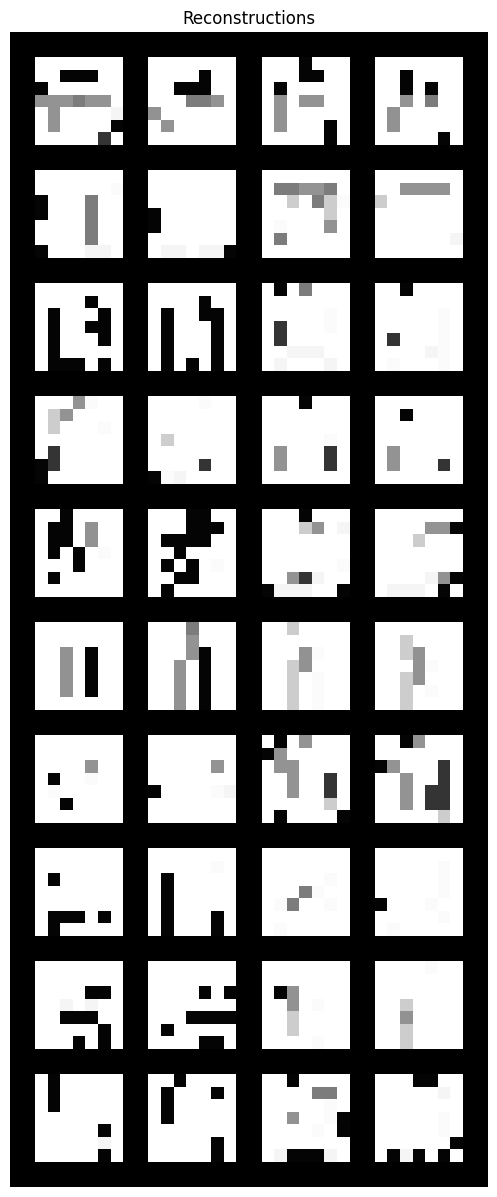

Epoch 6: 100%|██████████| 421/421 [00:14<00:00, 28.92it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


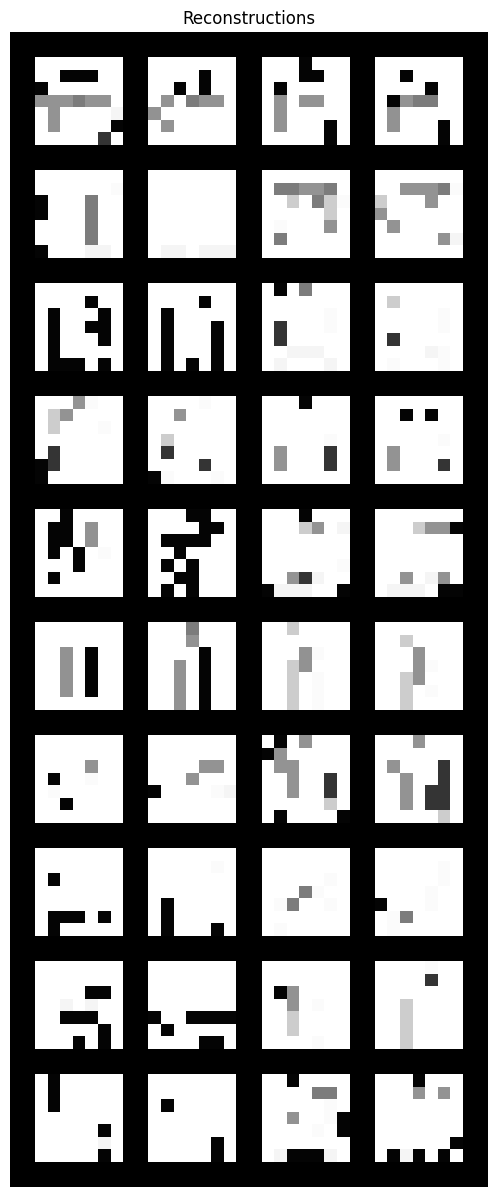

Epoch 7: 100%|██████████| 421/421 [00:14<00:00, 28.88it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


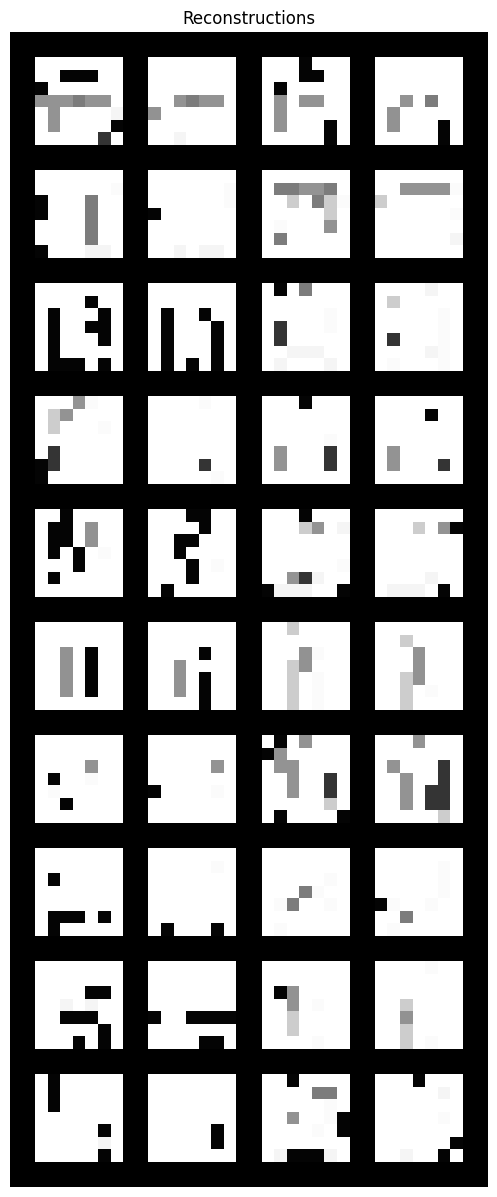

Epoch 8: 100%|██████████| 421/421 [00:14<00:00, 28.87it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


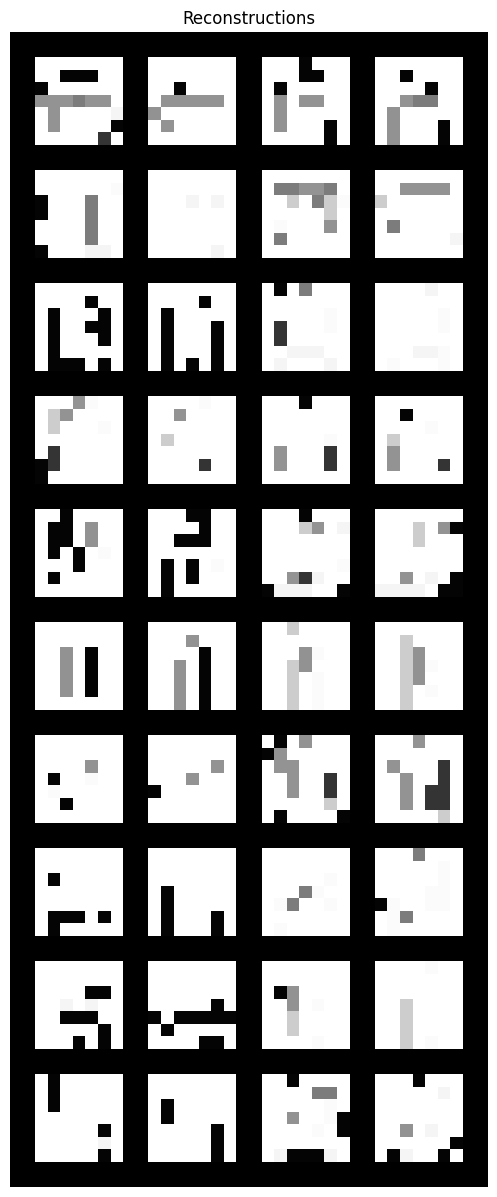

Epoch 9: 100%|██████████| 421/421 [00:15<00:00, 27.77it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


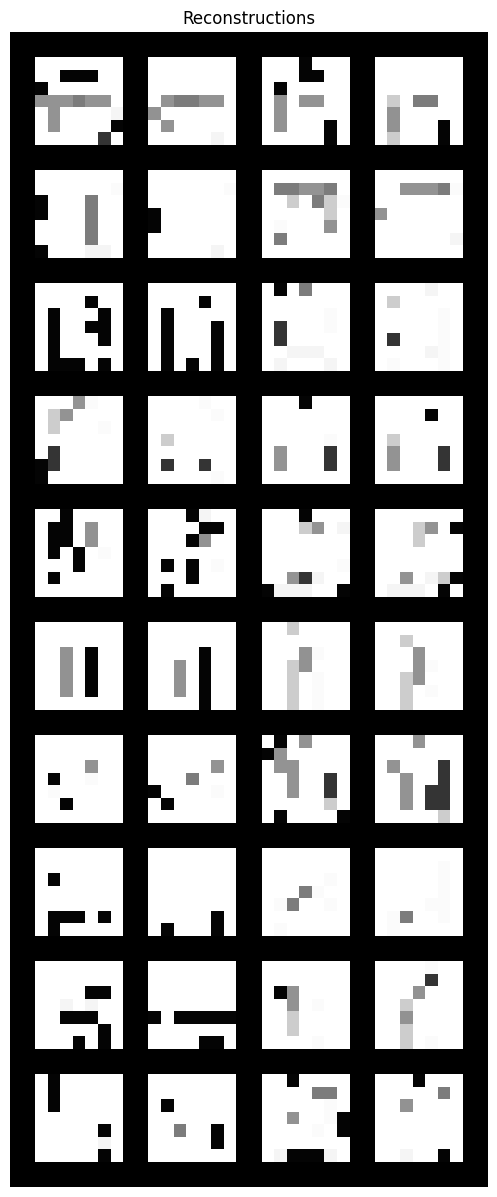

Epoch 10: 100%|██████████| 421/421 [00:15<00:00, 27.69it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


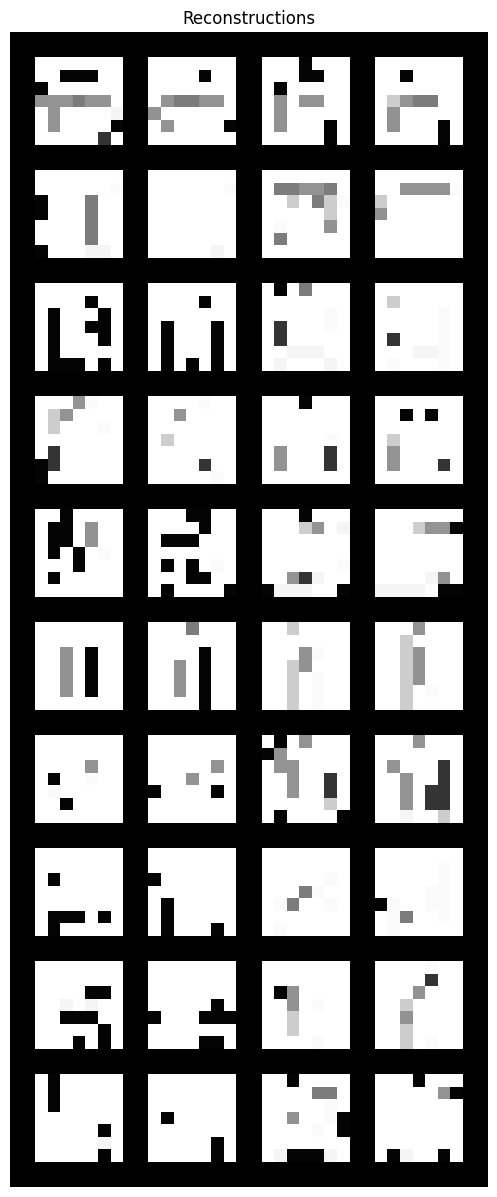

Epoch 11: 100%|██████████| 421/421 [00:14<00:00, 28.26it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


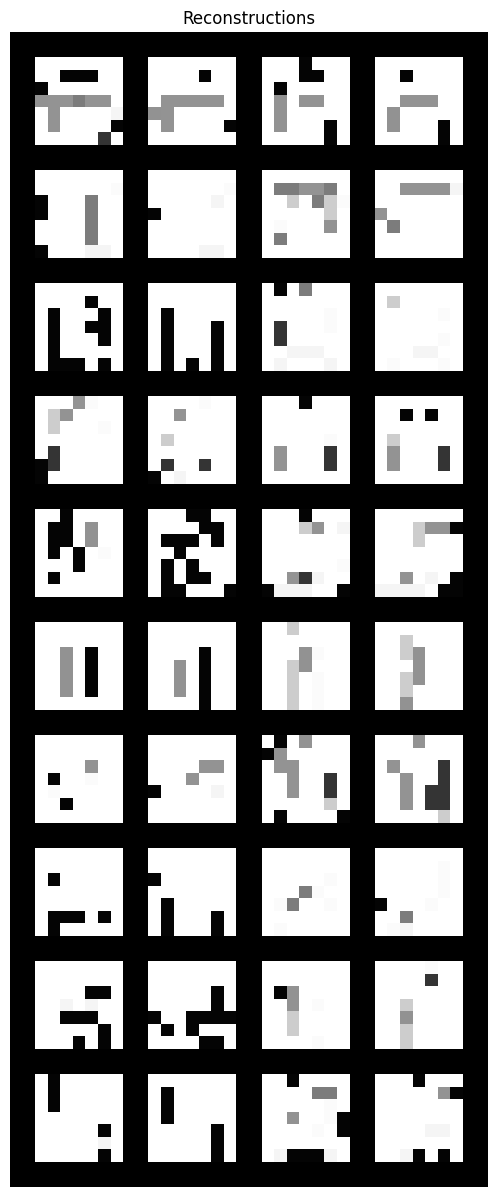

Epoch 12: 100%|██████████| 421/421 [00:15<00:00, 27.98it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


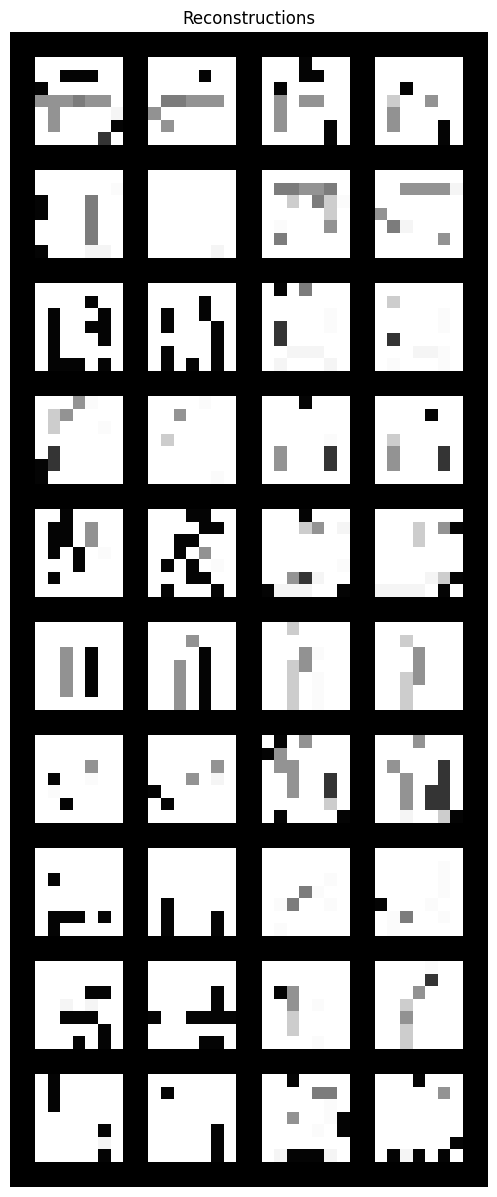

Epoch 13: 100%|██████████| 421/421 [00:14<00:00, 28.35it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


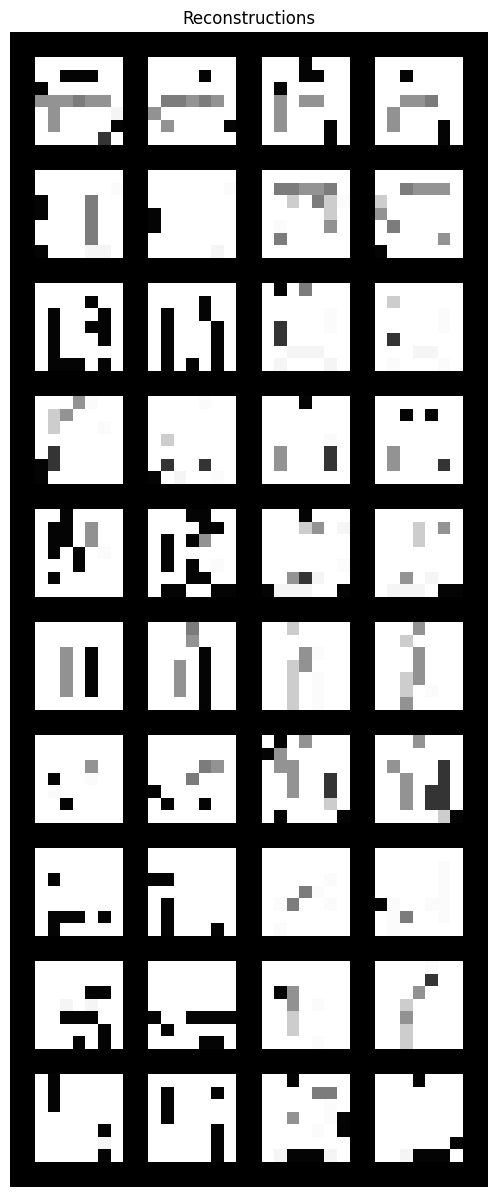

Epoch 14: 100%|██████████| 421/421 [00:15<00:00, 26.69it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


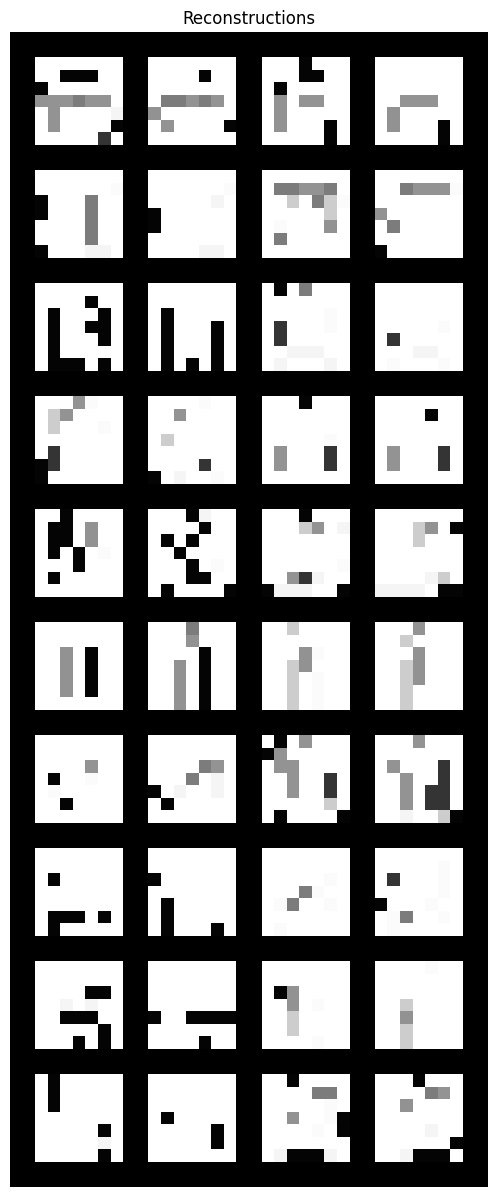

Epoch 15: 100%|██████████| 421/421 [00:15<00:00, 28.06it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


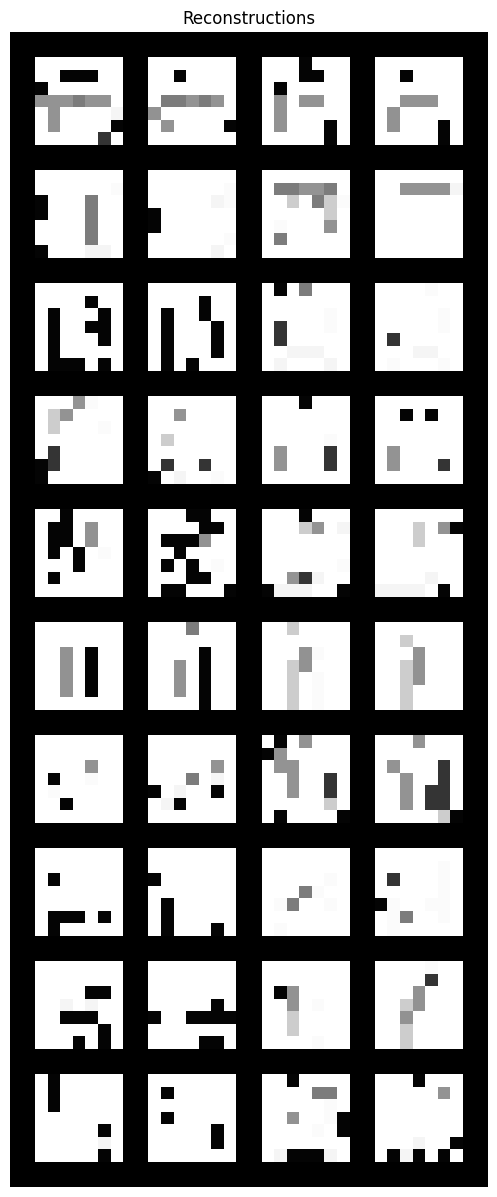

Epoch 16: 100%|██████████| 421/421 [00:14<00:00, 28.08it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


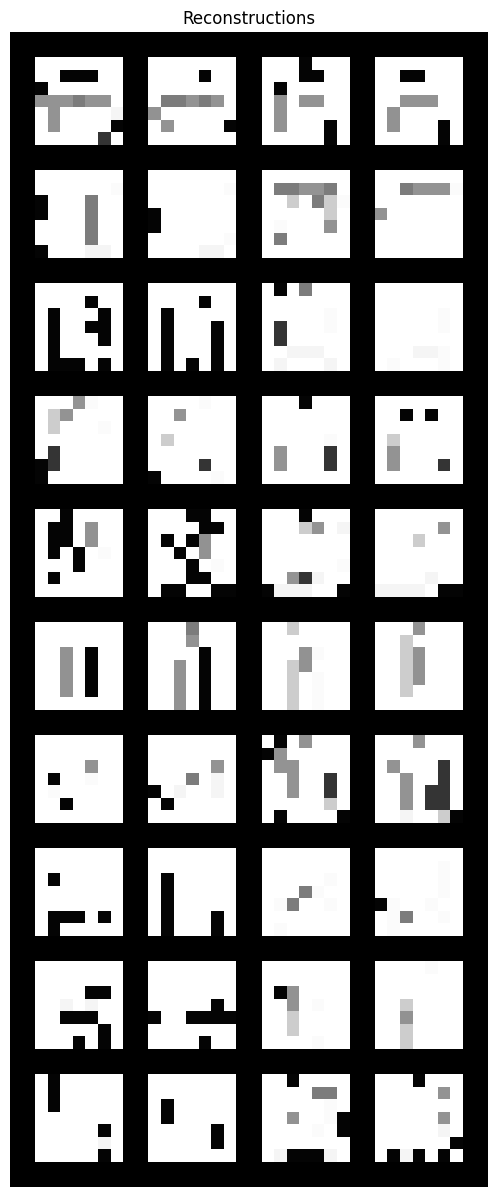

Epoch 17: 100%|██████████| 421/421 [00:15<00:00, 28.04it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


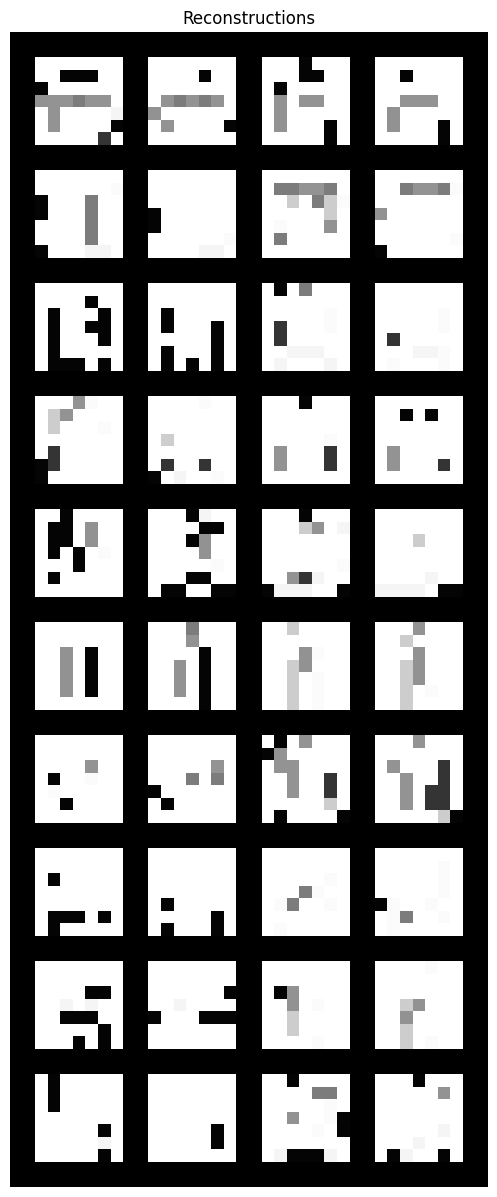

Epoch 18: 100%|██████████| 421/421 [00:15<00:00, 28.02it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


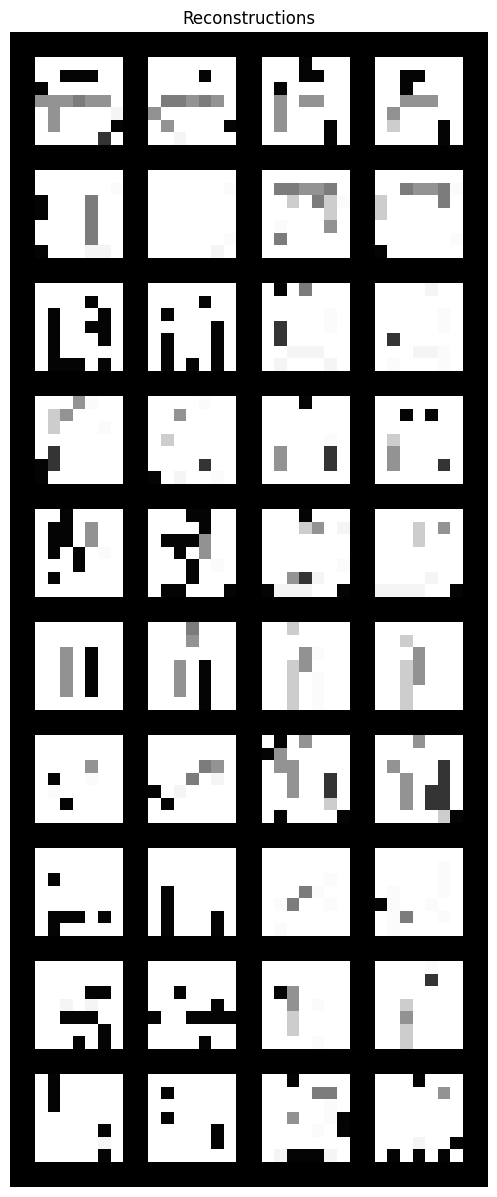

Epoch 19: 100%|██████████| 421/421 [00:15<00:00, 27.71it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


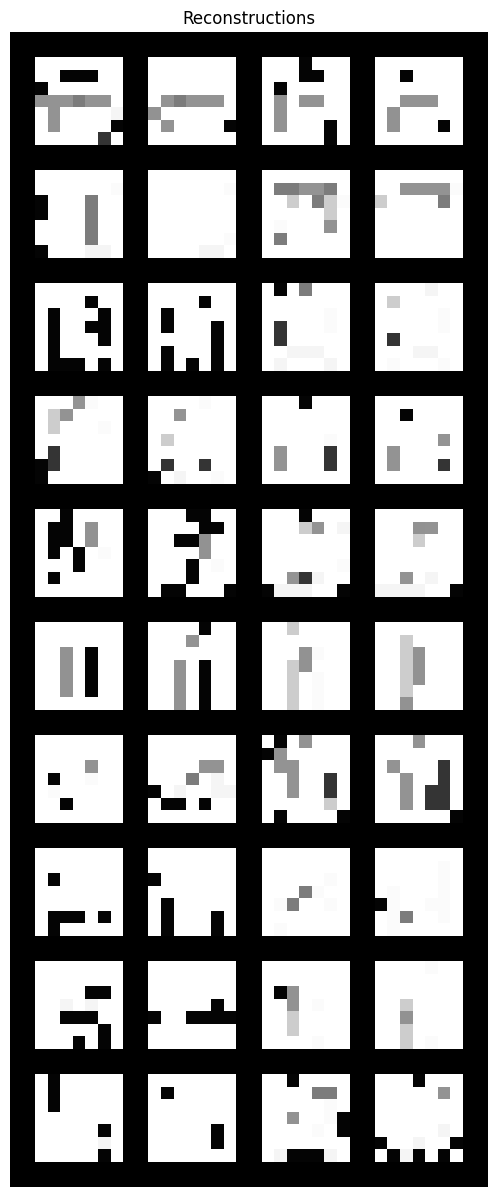

Epoch 20: 100%|██████████| 421/421 [00:15<00:00, 27.28it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


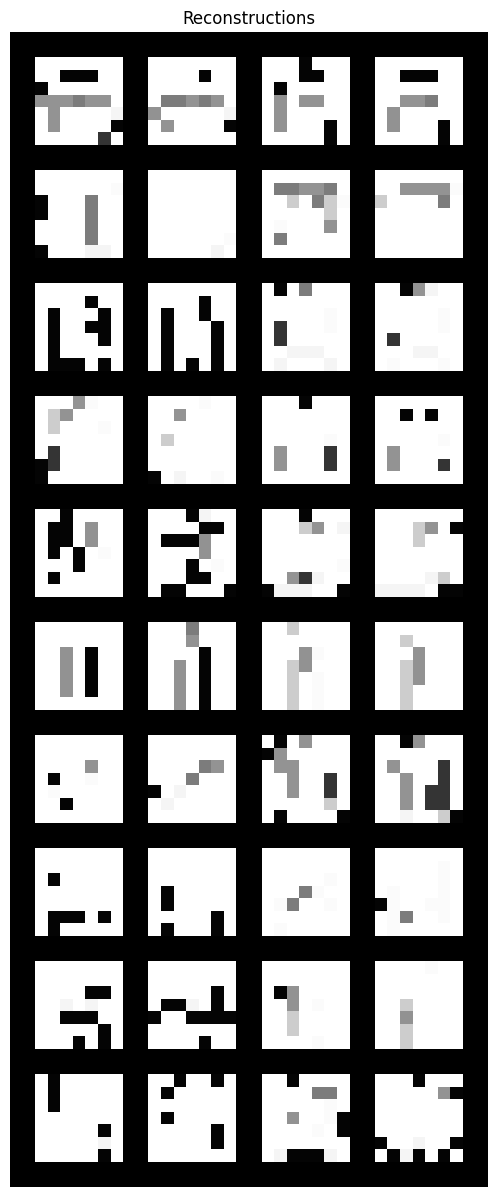

Epoch 21: 100%|██████████| 421/421 [00:15<00:00, 27.68it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


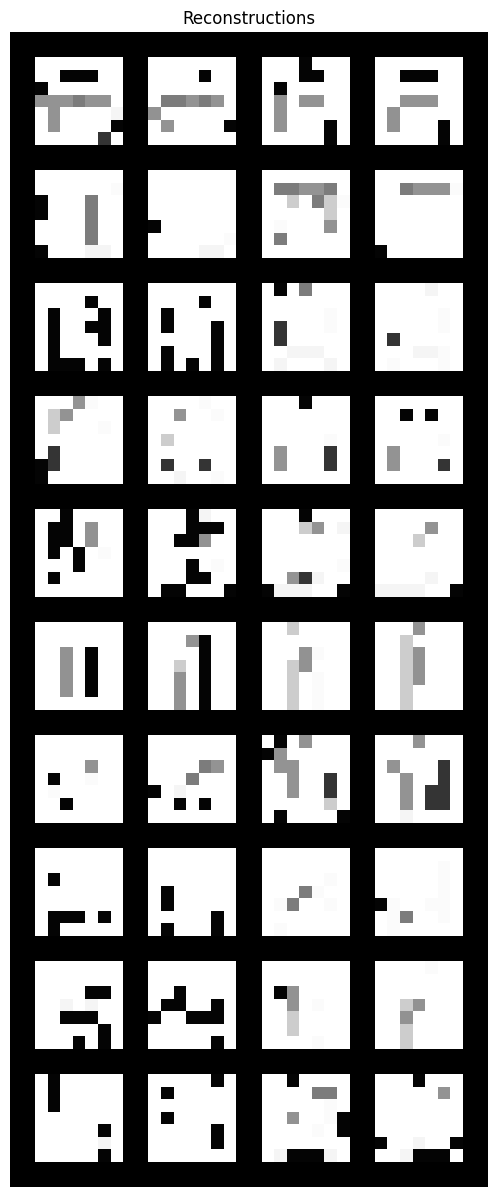

Epoch 22: 100%|██████████| 421/421 [00:14<00:00, 28.40it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


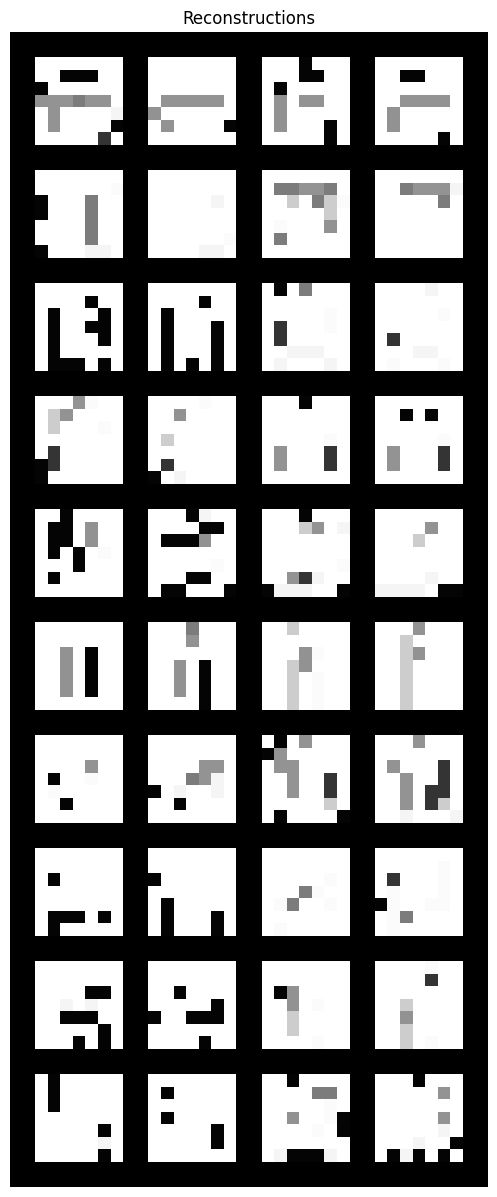

Epoch 23: 100%|██████████| 421/421 [00:14<00:00, 28.88it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


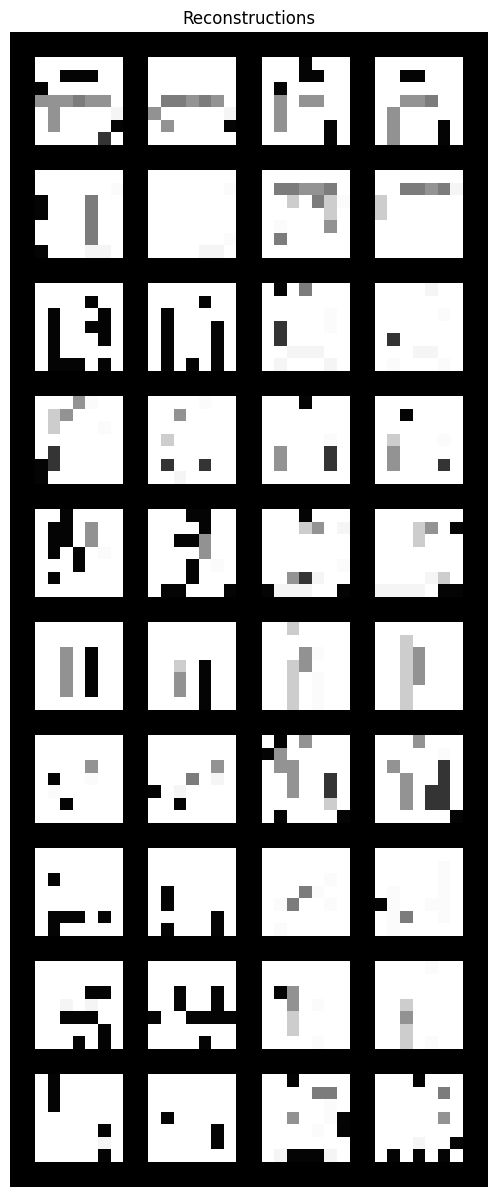

Epoch 24: 100%|██████████| 421/421 [00:14<00:00, 28.89it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


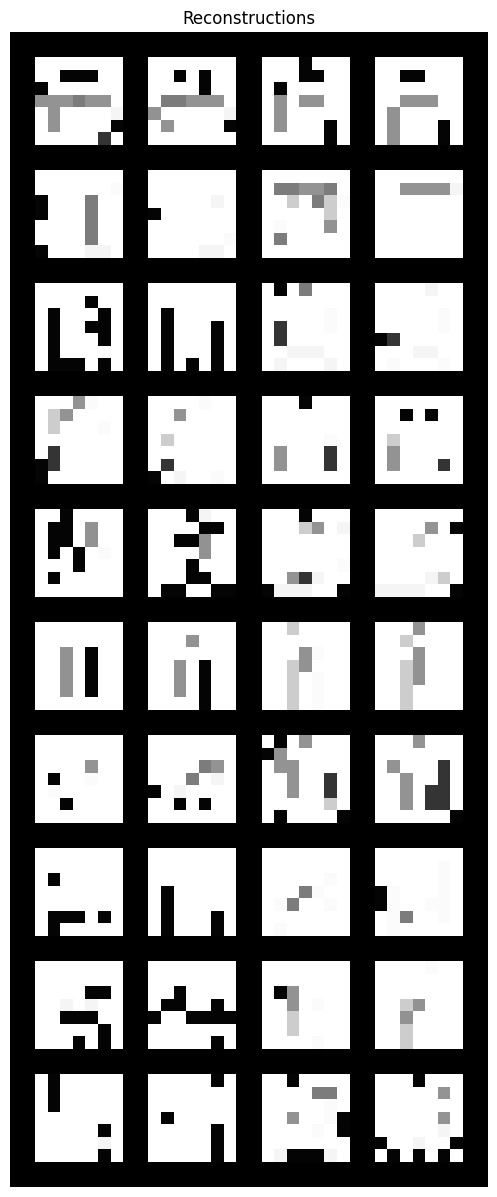

Epoch 25: 100%|██████████| 421/421 [00:14<00:00, 28.89it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


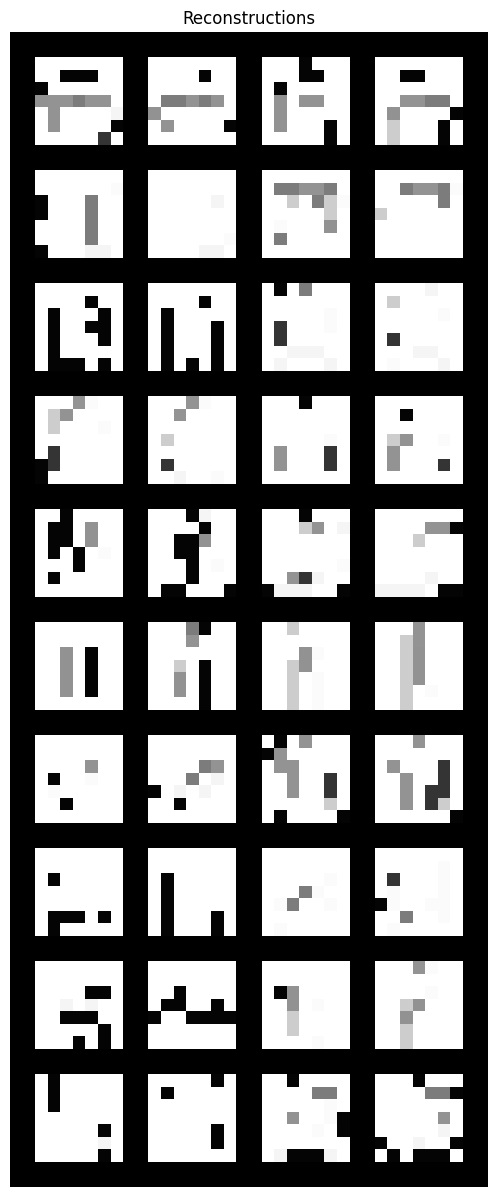

Epoch 26: 100%|██████████| 421/421 [00:14<00:00, 28.91it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


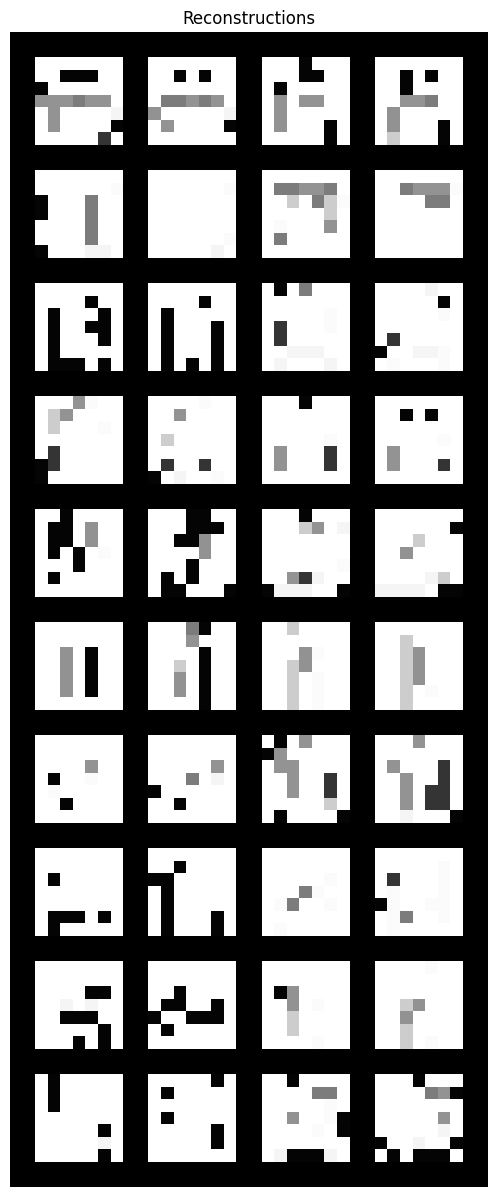

Epoch 27: 100%|██████████| 421/421 [00:14<00:00, 28.88it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


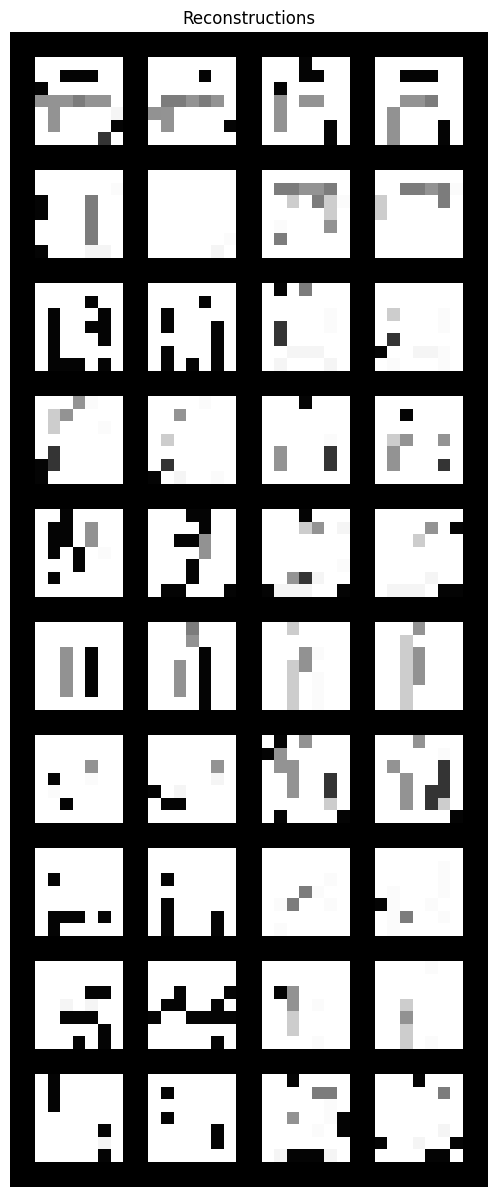

Epoch 28: 100%|██████████| 421/421 [00:14<00:00, 28.83it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


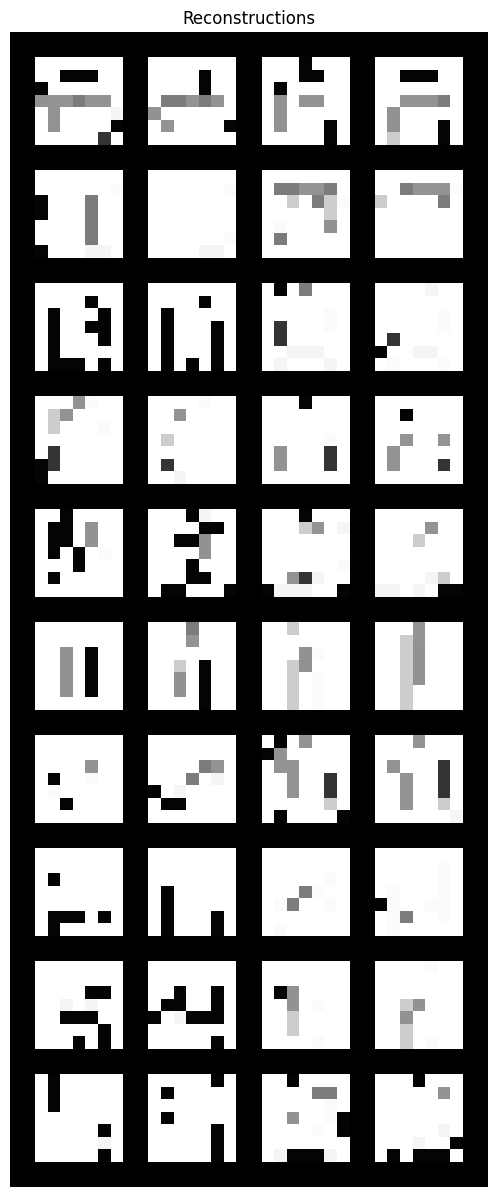

Epoch 29: 100%|██████████| 421/421 [00:14<00:00, 28.24it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


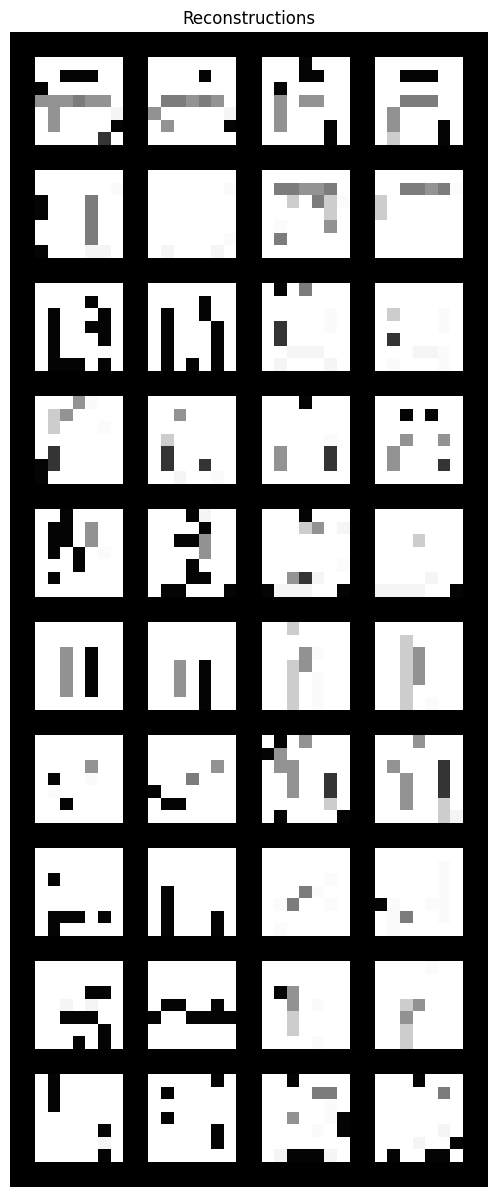

Epoch 30: 100%|██████████| 421/421 [00:14<00:00, 28.65it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


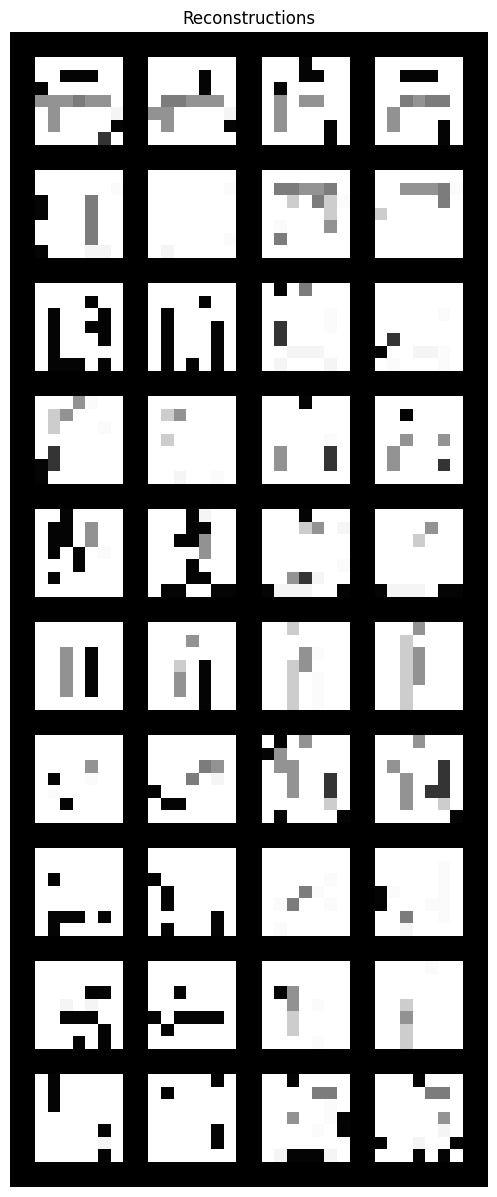

Epoch 31: 100%|██████████| 421/421 [00:14<00:00, 28.60it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


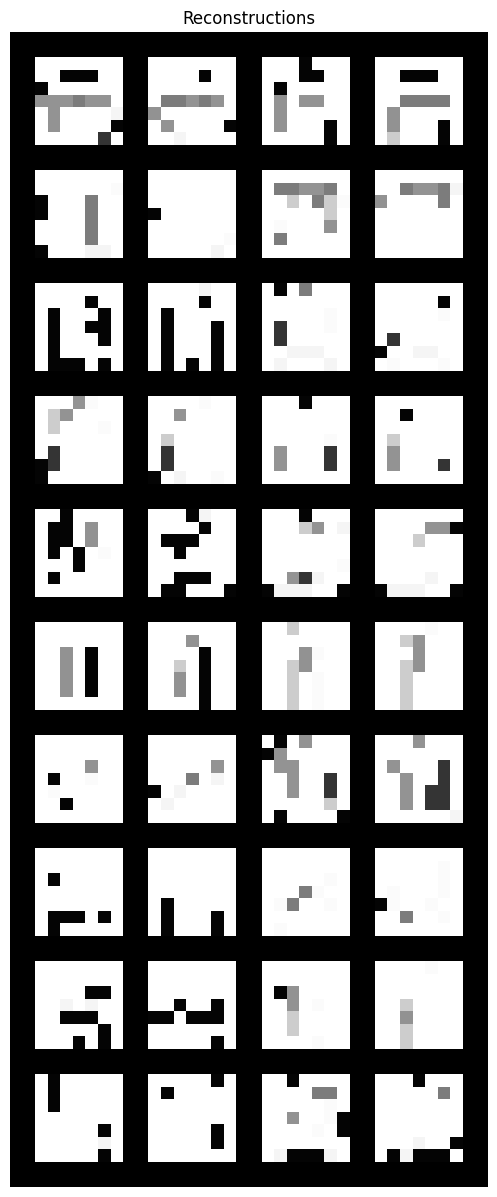

Epoch 32: 100%|██████████| 421/421 [00:14<00:00, 28.39it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


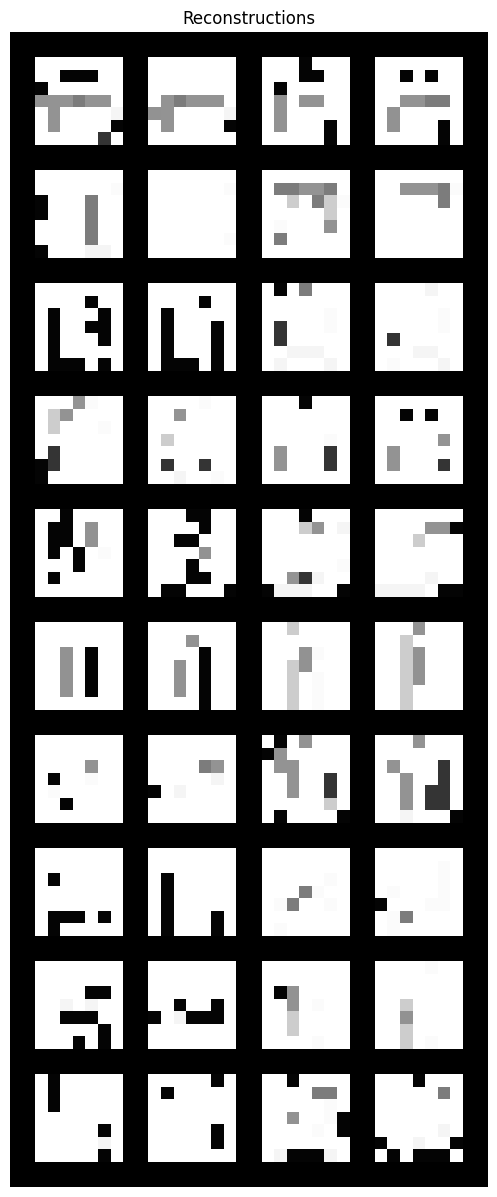

Epoch 33: 100%|██████████| 421/421 [00:14<00:00, 28.82it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


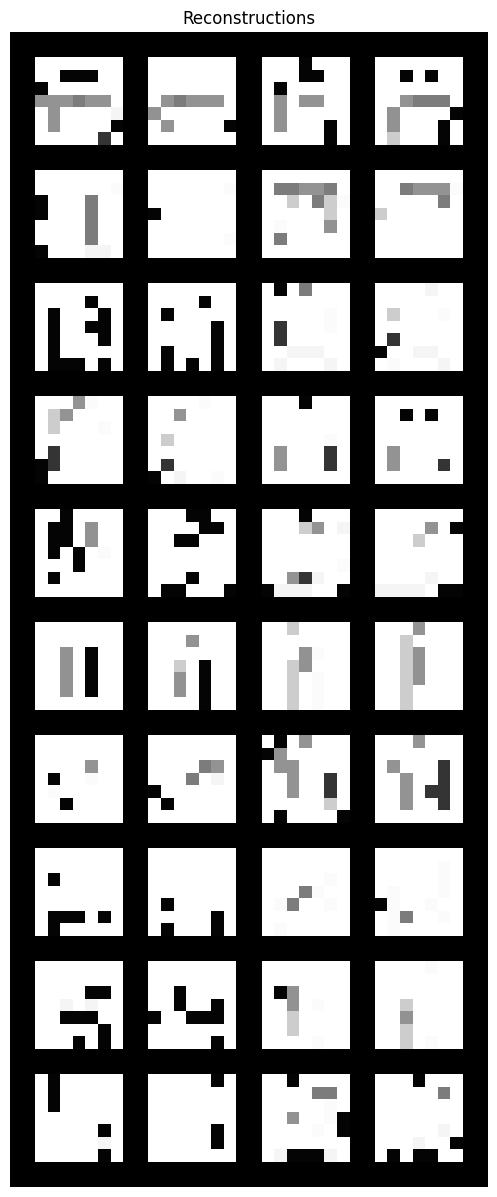

Epoch 34: 100%|██████████| 421/421 [00:14<00:00, 28.75it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


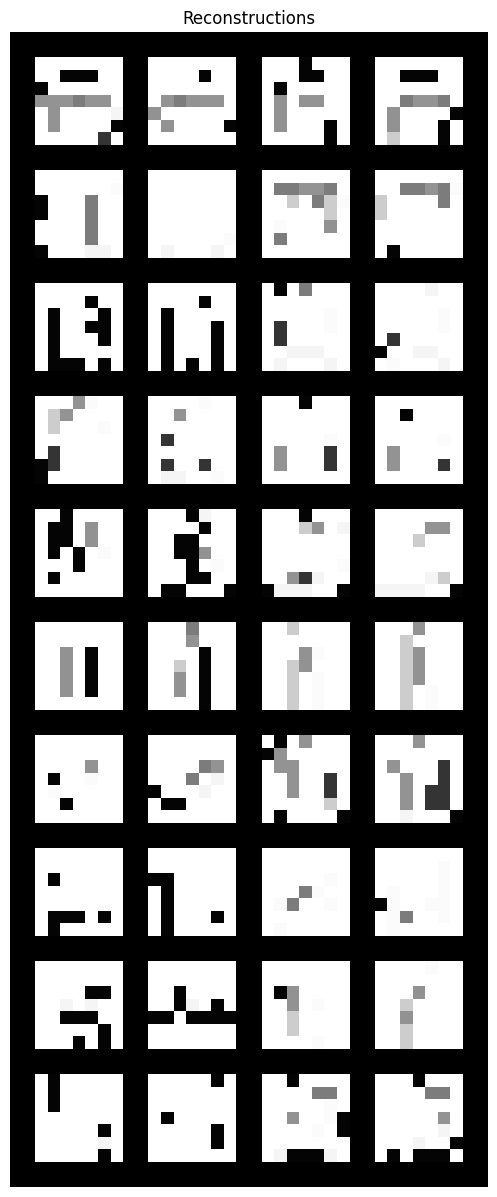

Epoch 35: 100%|██████████| 421/421 [00:14<00:00, 28.79it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


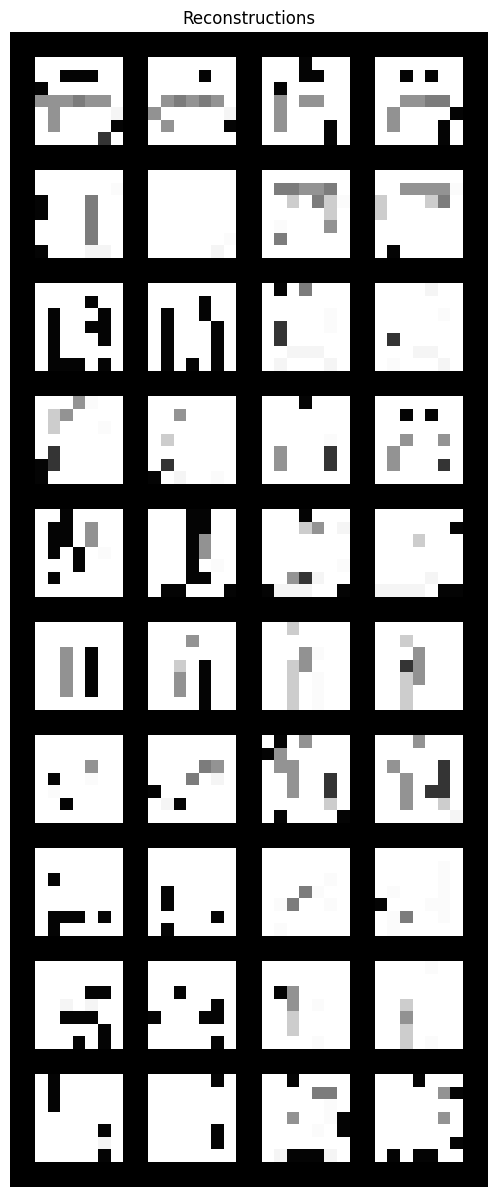

Epoch 36: 100%|██████████| 421/421 [00:14<00:00, 28.80it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


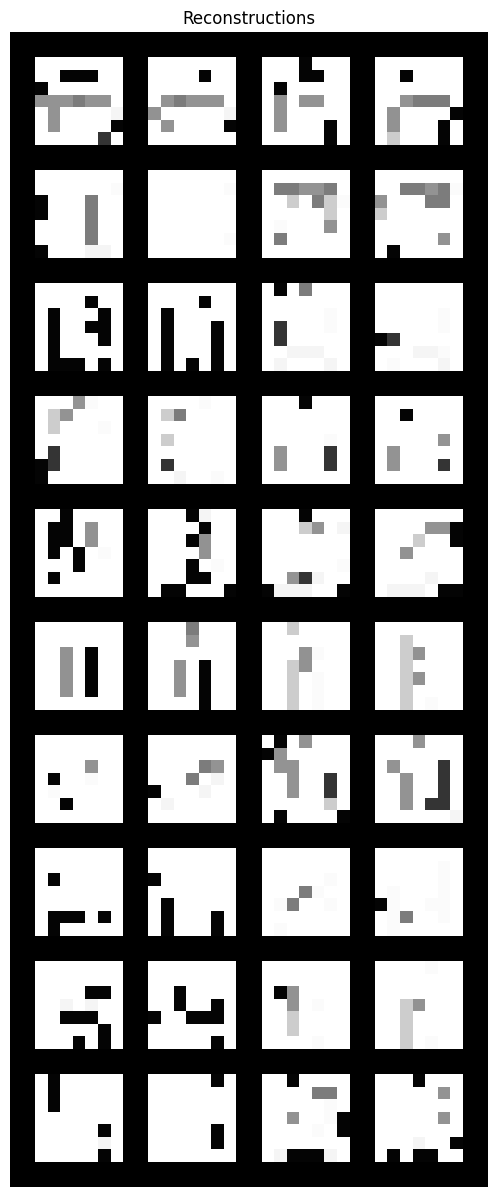

Epoch 37: 100%|██████████| 421/421 [00:14<00:00, 28.73it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


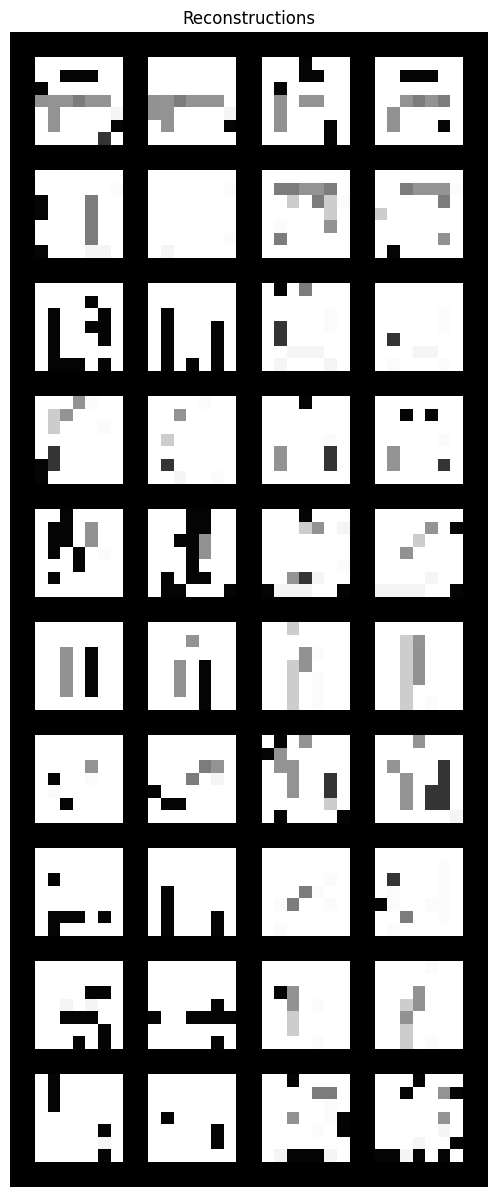

Epoch 38: 100%|██████████| 421/421 [00:15<00:00, 27.12it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


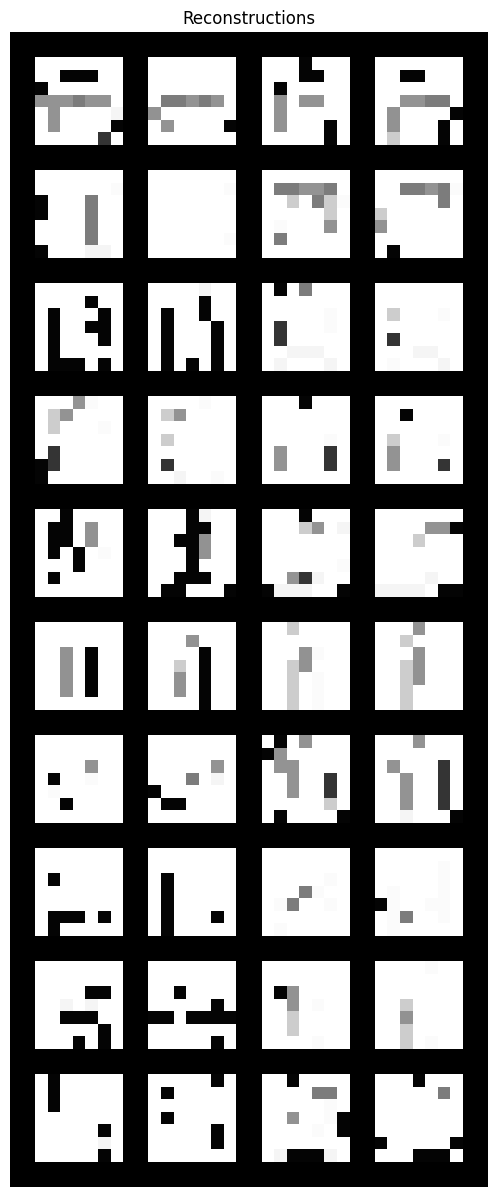

Epoch 39: 100%|██████████| 421/421 [00:15<00:00, 26.97it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


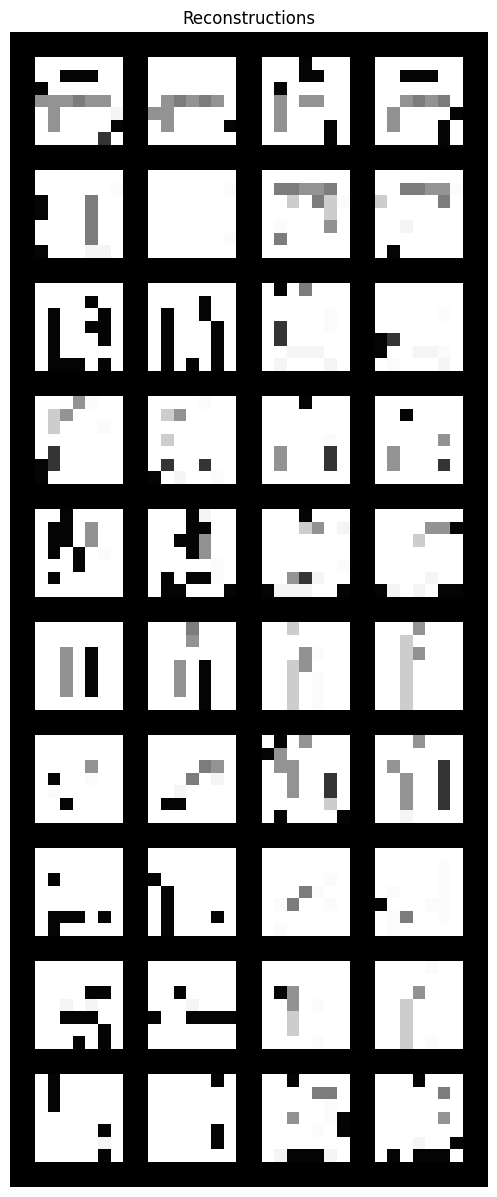

Epoch 40: 100%|██████████| 421/421 [00:15<00:00, 27.33it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


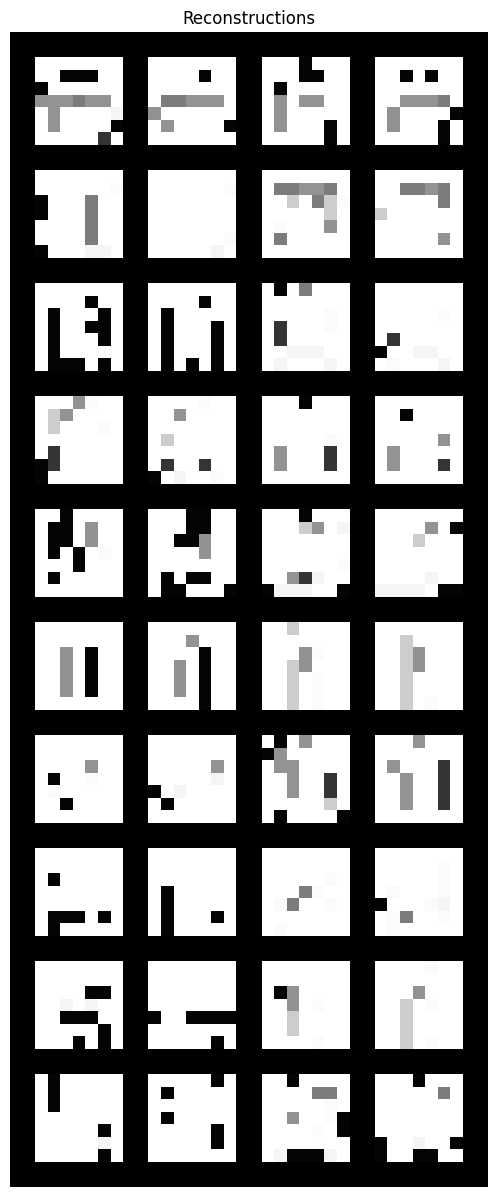

Epoch 41: 100%|██████████| 421/421 [00:14<00:00, 28.17it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


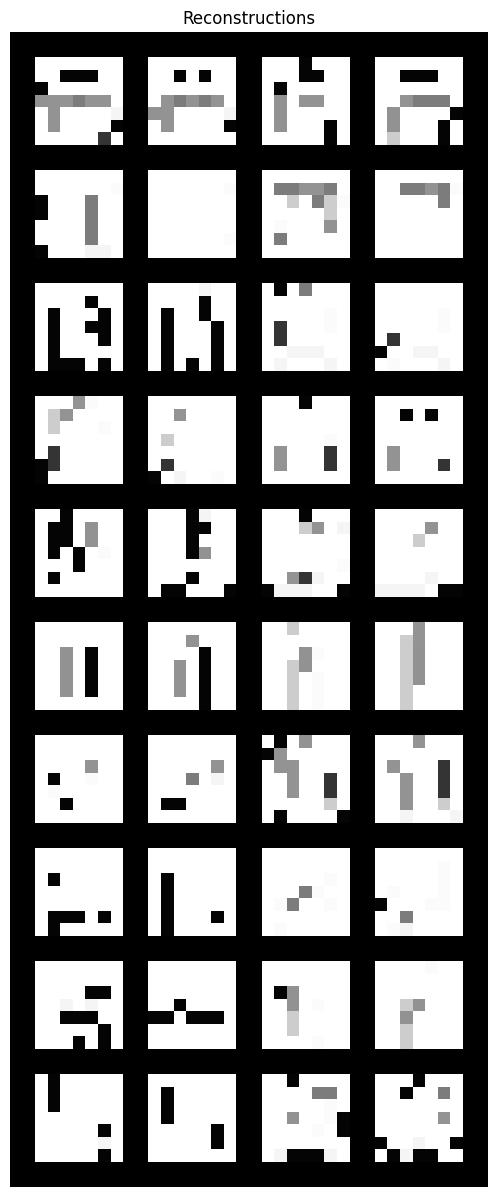

Epoch 42: 100%|██████████| 421/421 [00:15<00:00, 27.80it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


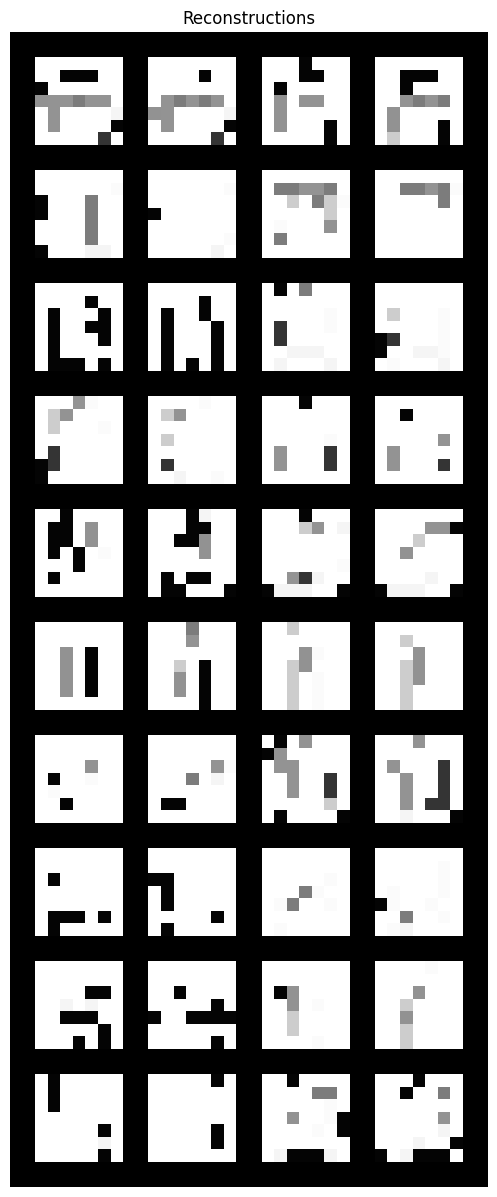

Epoch 43: 100%|██████████| 421/421 [00:15<00:00, 26.96it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


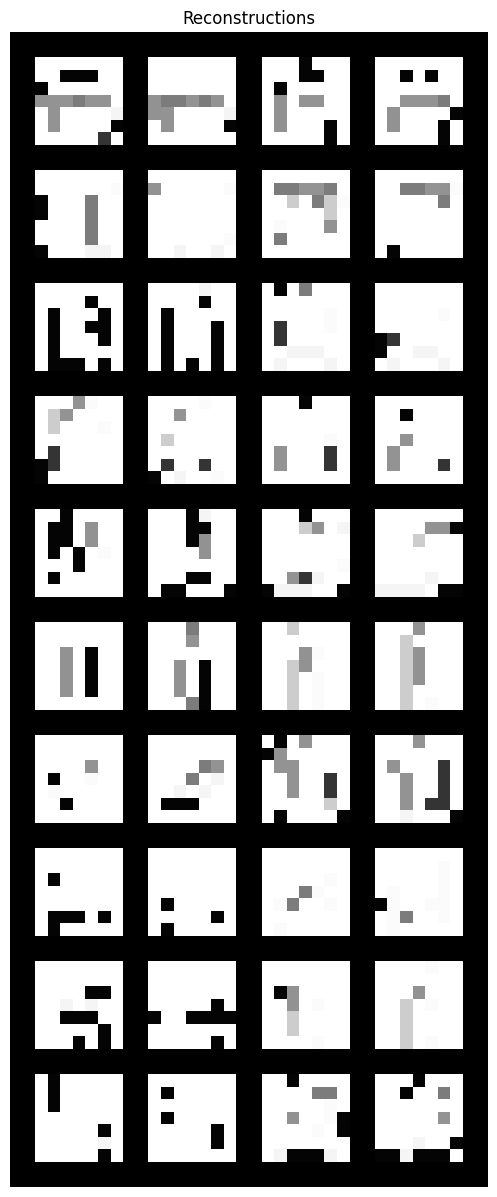

Epoch 44: 100%|██████████| 421/421 [00:14<00:00, 28.44it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


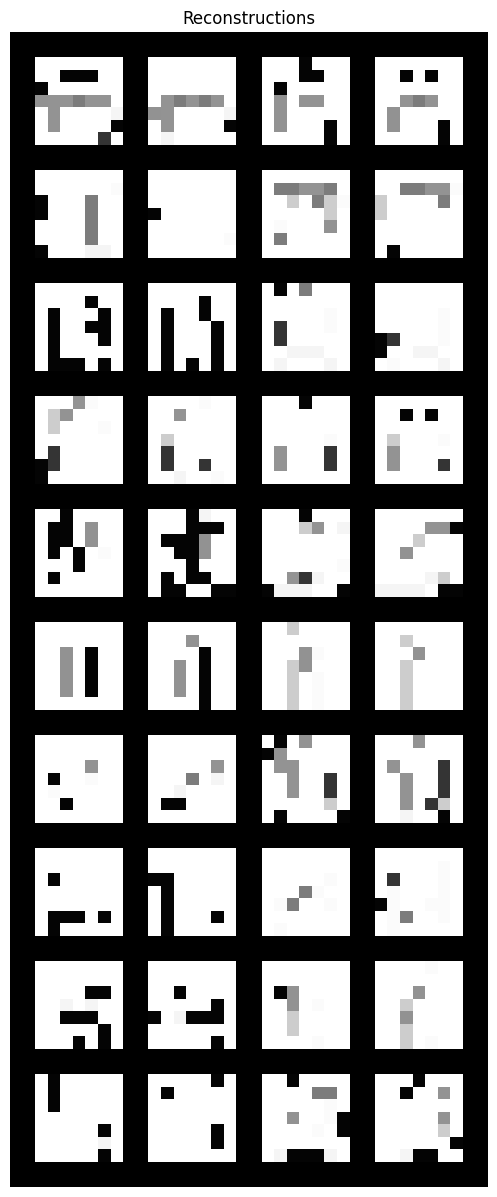

Epoch 45: 100%|██████████| 421/421 [00:14<00:00, 28.44it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


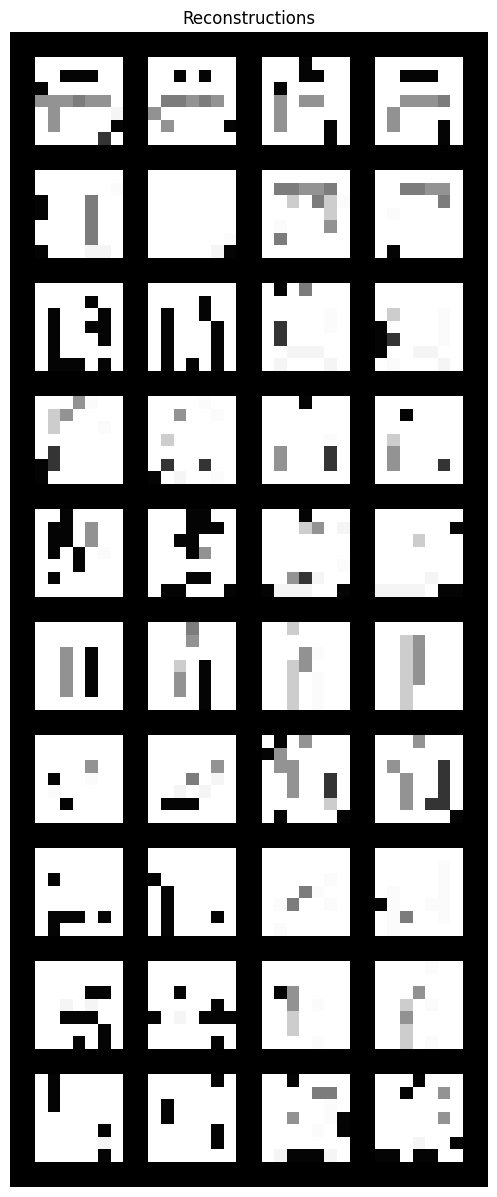

Epoch 46: 100%|██████████| 421/421 [00:14<00:00, 28.38it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


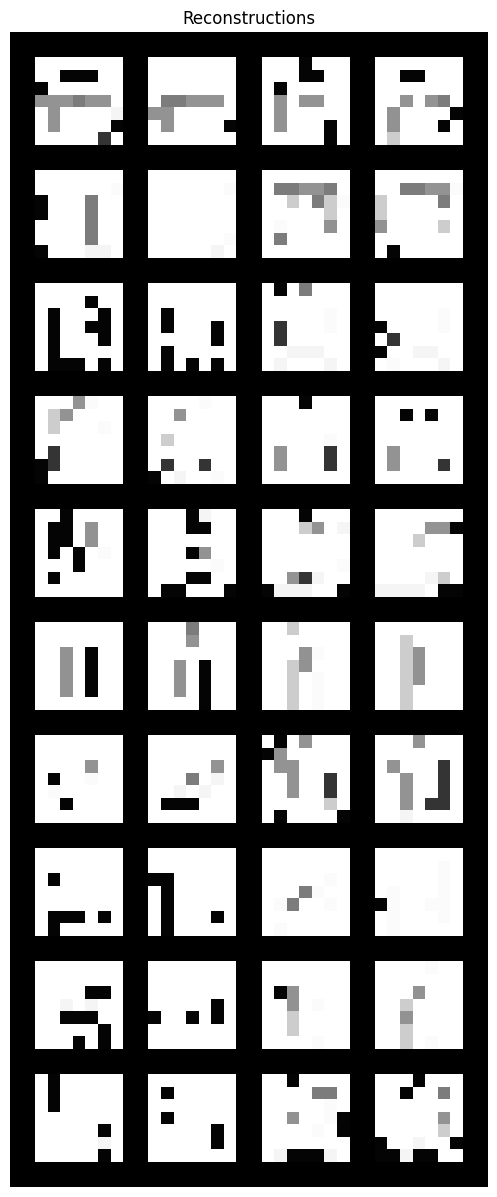

Epoch 47: 100%|██████████| 421/421 [00:14<00:00, 28.42it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


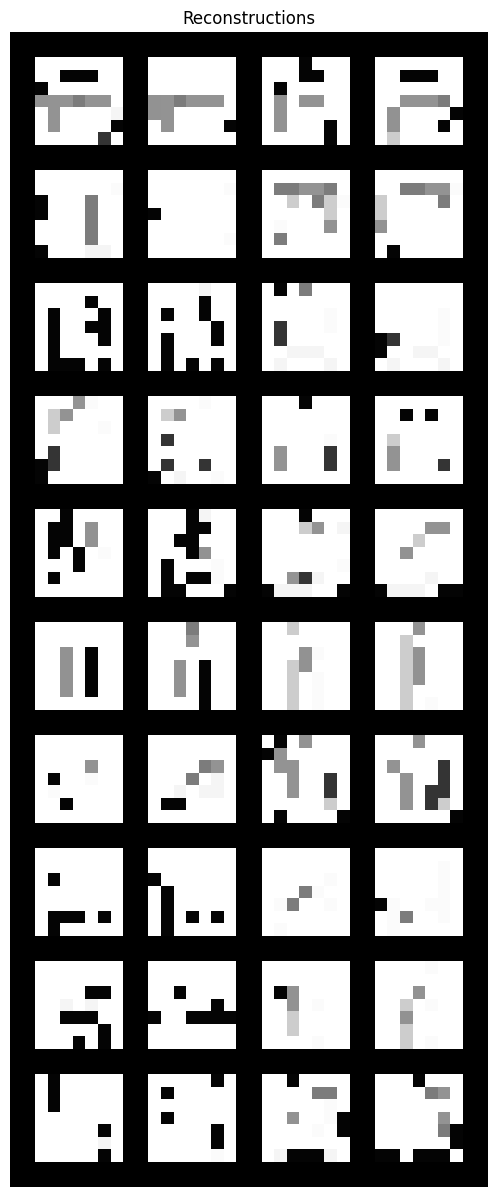

Epoch 48: 100%|██████████| 421/421 [00:14<00:00, 28.46it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


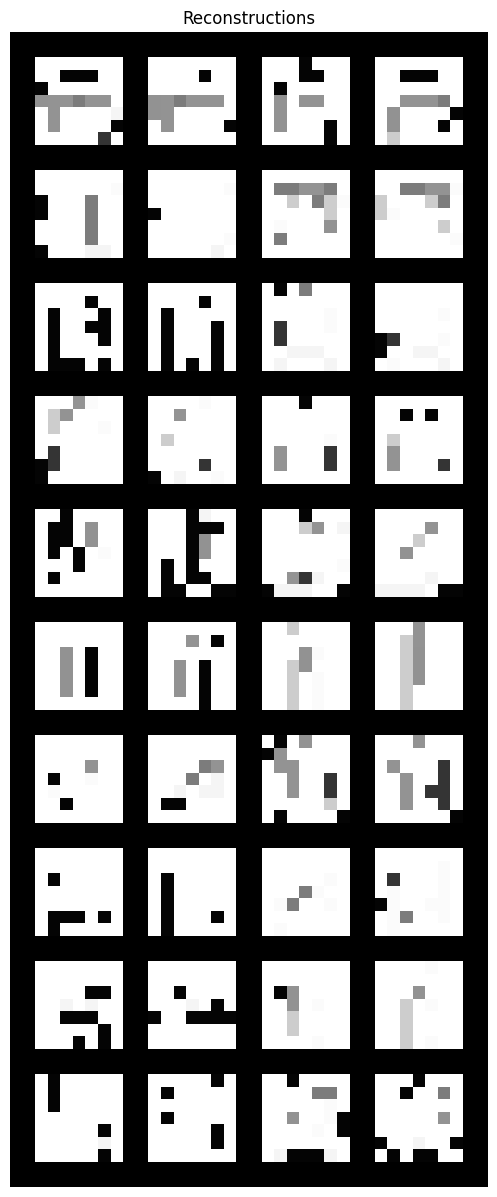

Epoch 49: 100%|██████████| 421/421 [00:14<00:00, 28.45it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


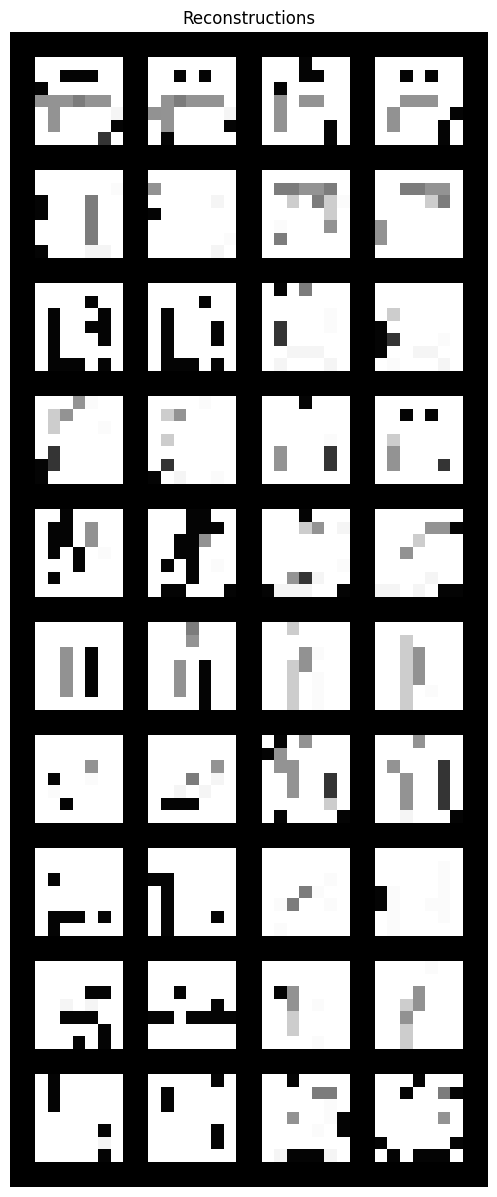

Epoch 50: 100%|██████████| 421/421 [00:14<00:00, 28.45it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


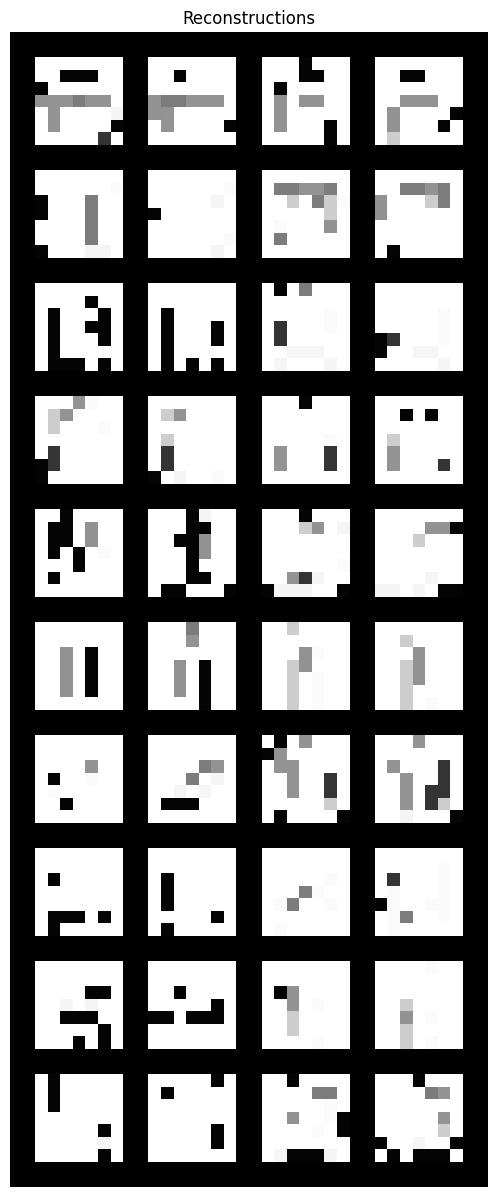

Epoch 51: 100%|██████████| 421/421 [00:14<00:00, 28.41it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


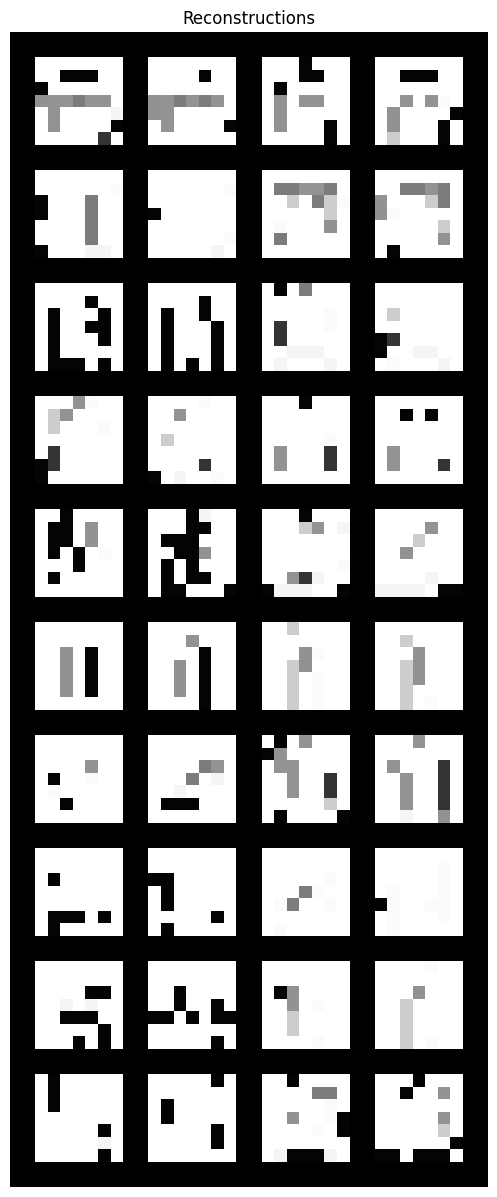

Epoch 52: 100%|██████████| 421/421 [00:14<00:00, 28.38it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


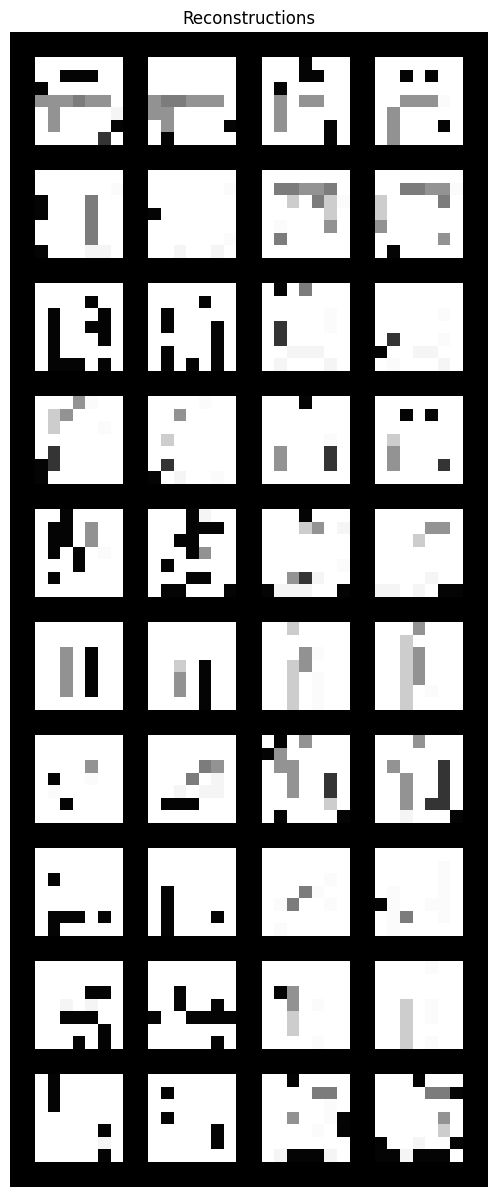

Epoch 53: 100%|██████████| 421/421 [00:14<00:00, 28.42it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


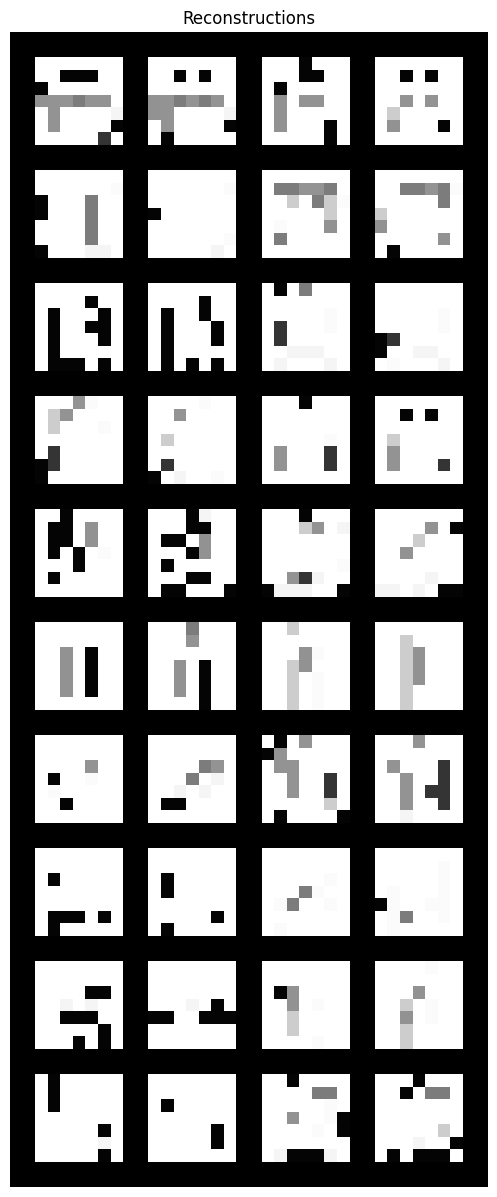

Epoch 54: 100%|██████████| 421/421 [00:14<00:00, 28.12it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


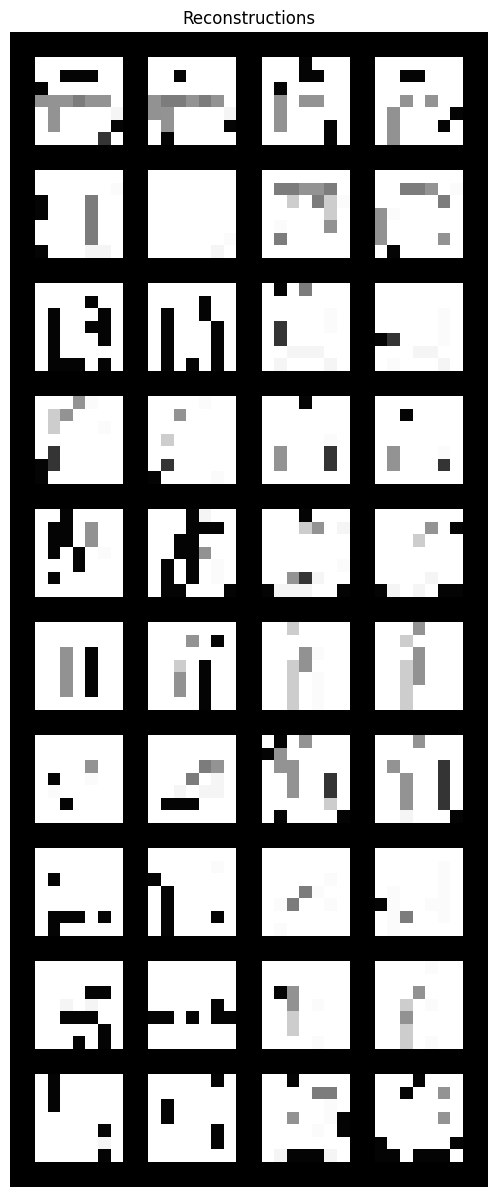

Epoch 55: 100%|██████████| 421/421 [00:14<00:00, 28.39it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


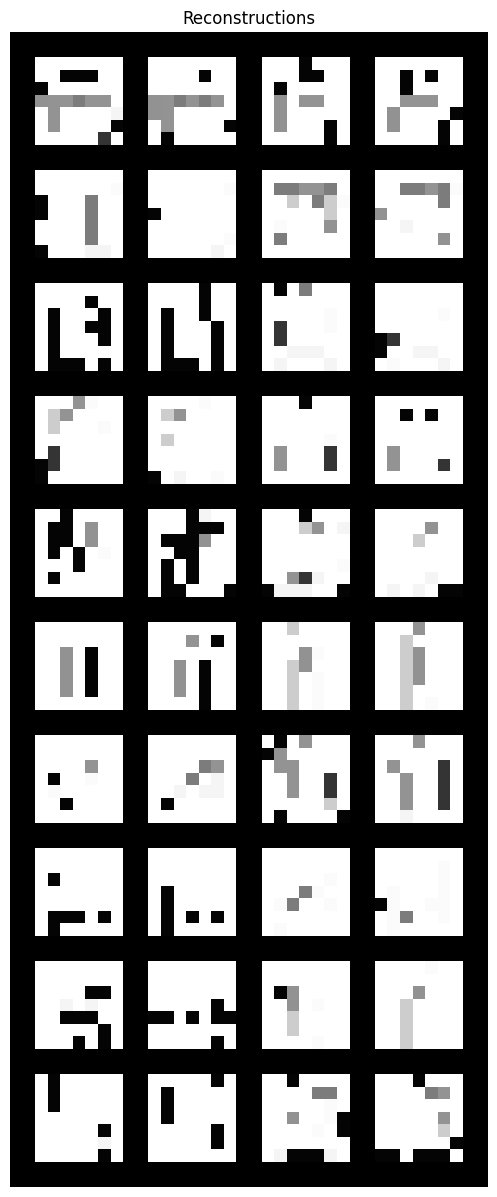

Epoch 56: 100%|██████████| 421/421 [00:14<00:00, 28.40it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


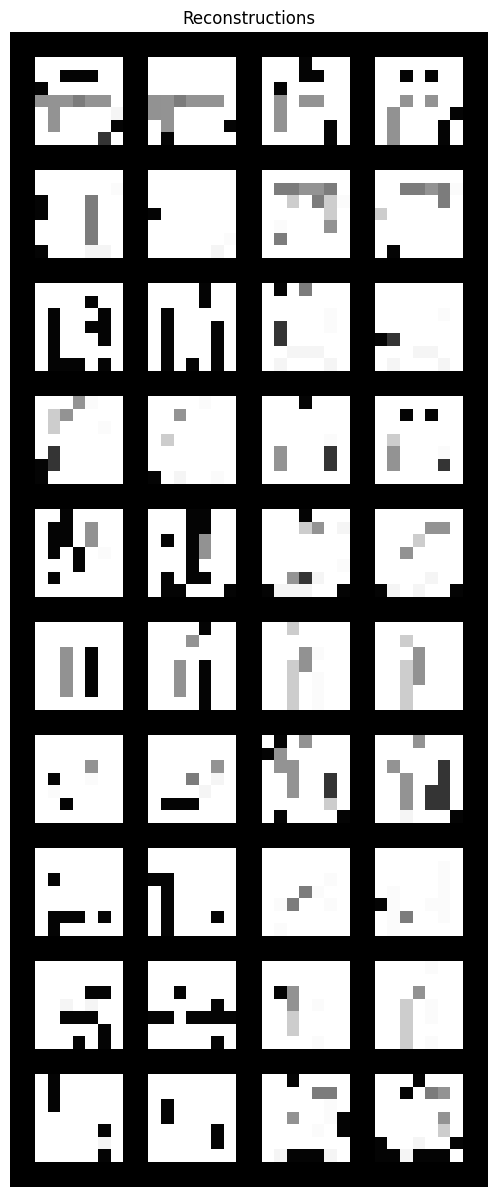

Epoch 57: 100%|██████████| 421/421 [00:15<00:00, 27.55it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


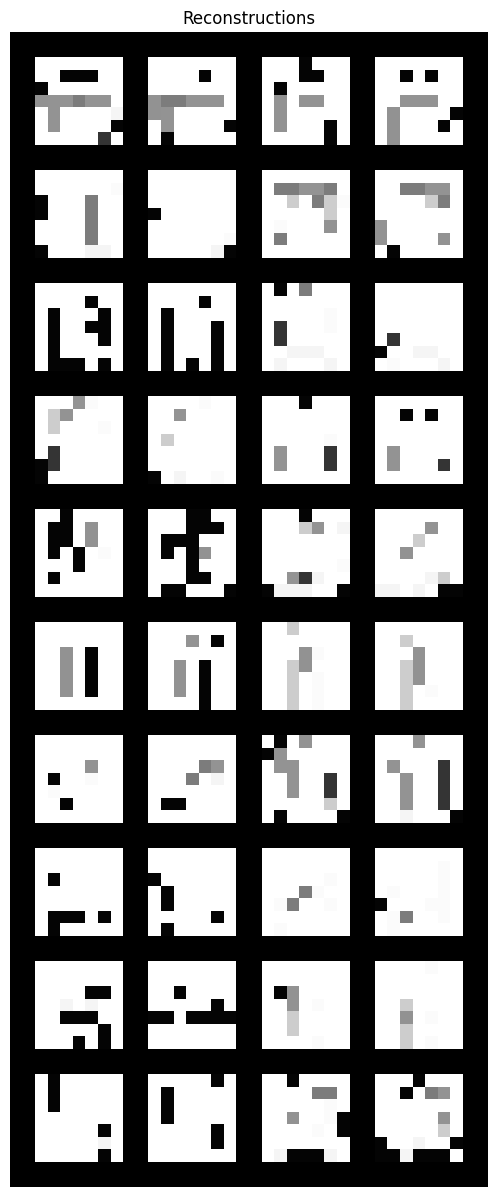

Epoch 58: 100%|██████████| 421/421 [00:15<00:00, 27.25it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


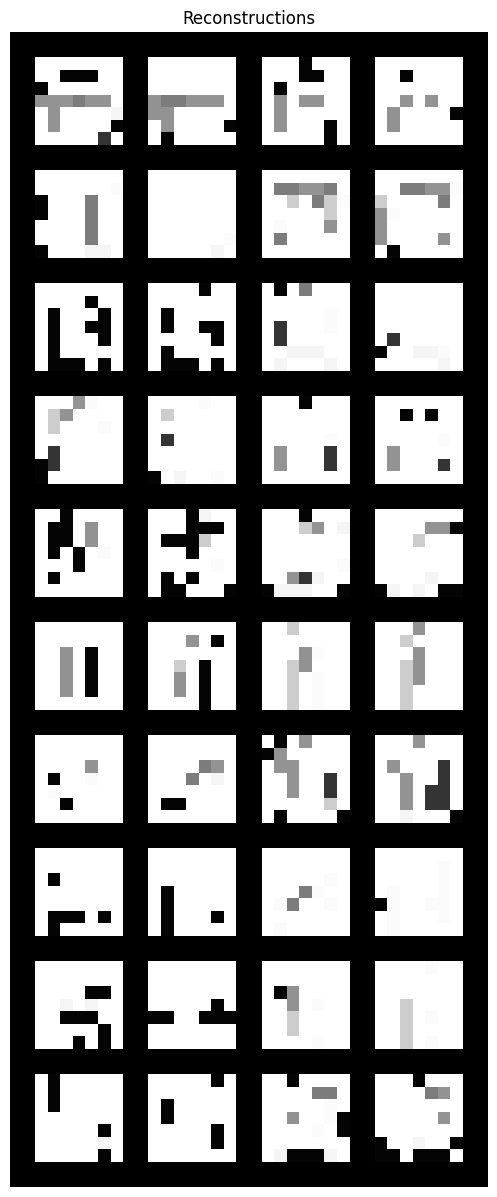

Epoch 59: 100%|██████████| 421/421 [00:14<00:00, 28.37it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


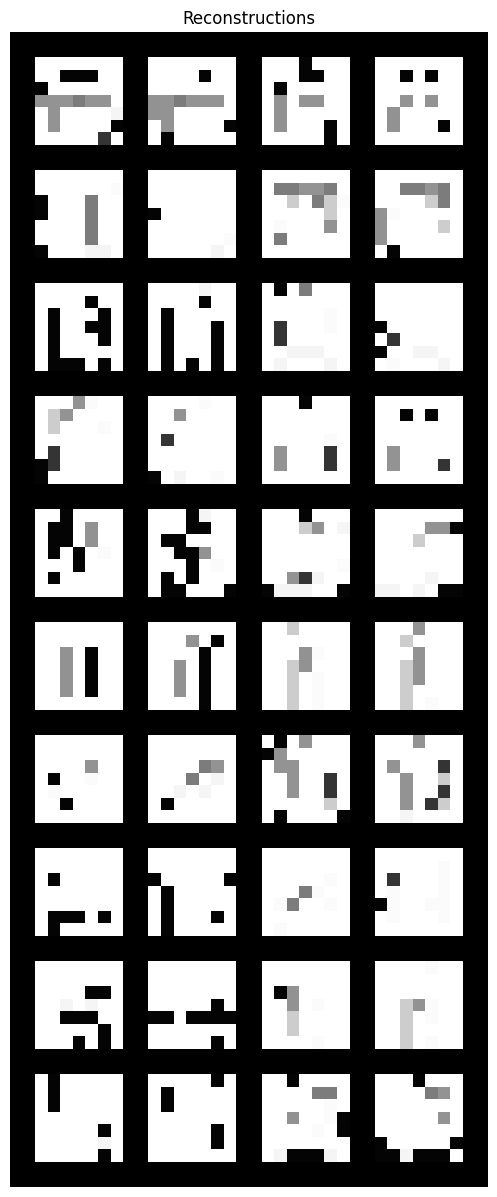

Epoch 60: 100%|██████████| 421/421 [00:14<00:00, 28.17it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


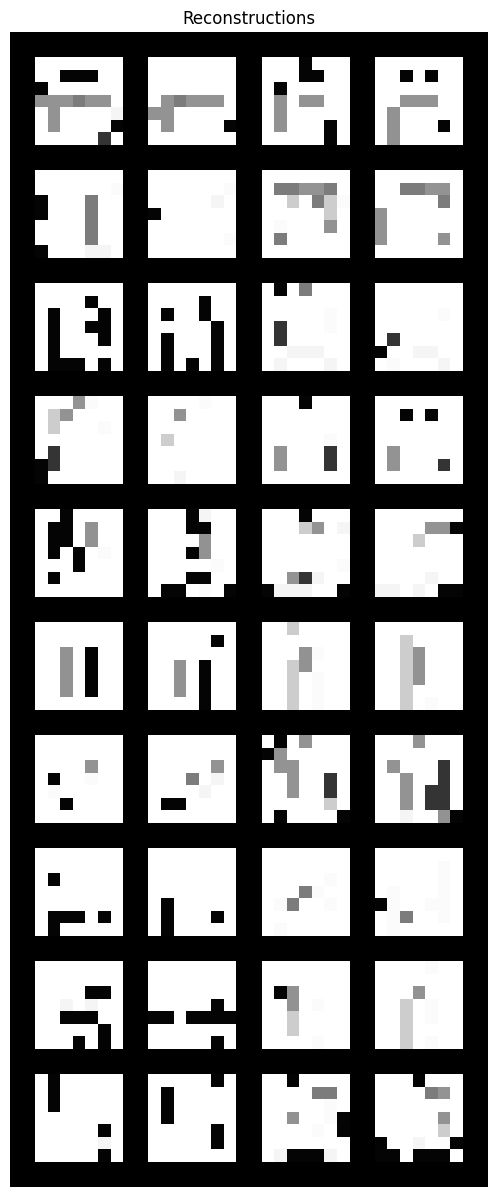

Epoch 61: 100%|██████████| 421/421 [00:14<00:00, 28.39it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


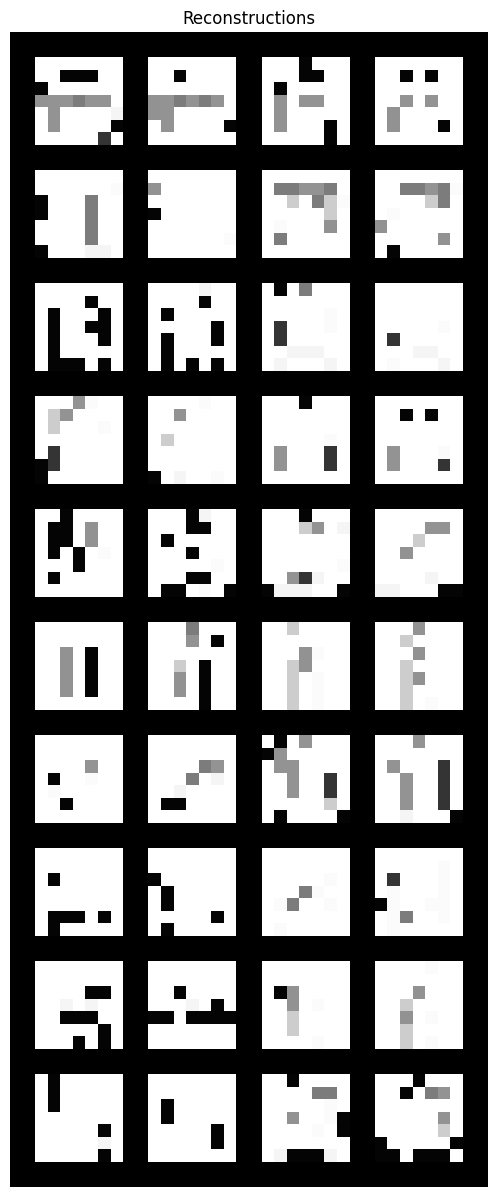

Epoch 62: 100%|██████████| 421/421 [00:14<00:00, 28.41it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


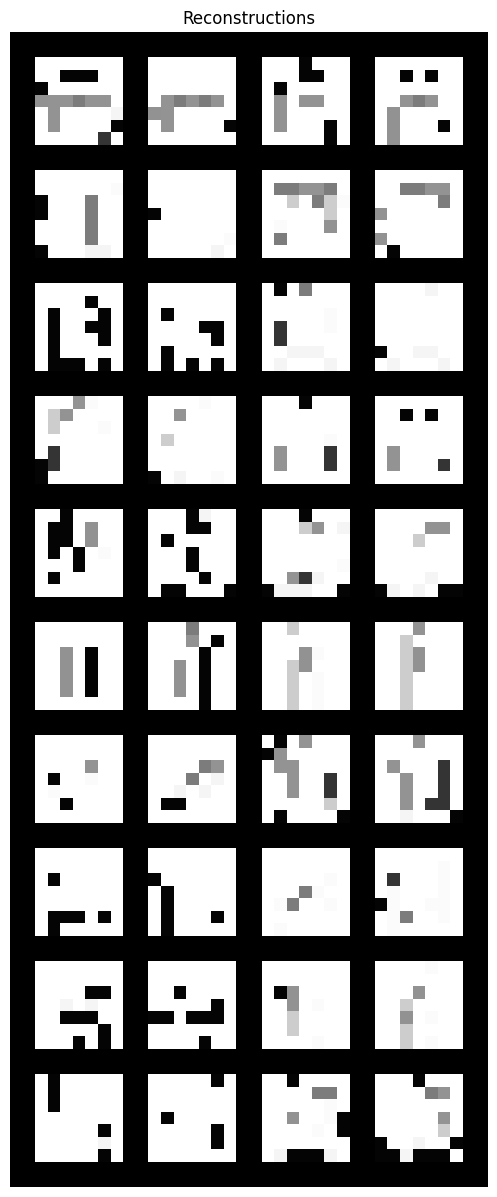

Epoch 63: 100%|██████████| 421/421 [00:14<00:00, 28.42it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


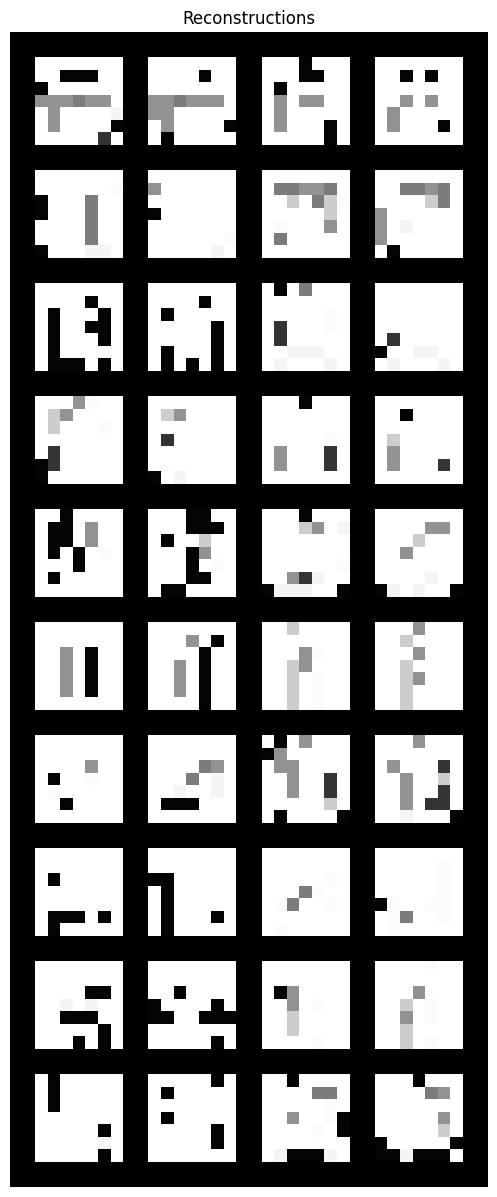

Epoch 64: 100%|██████████| 421/421 [00:14<00:00, 28.39it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


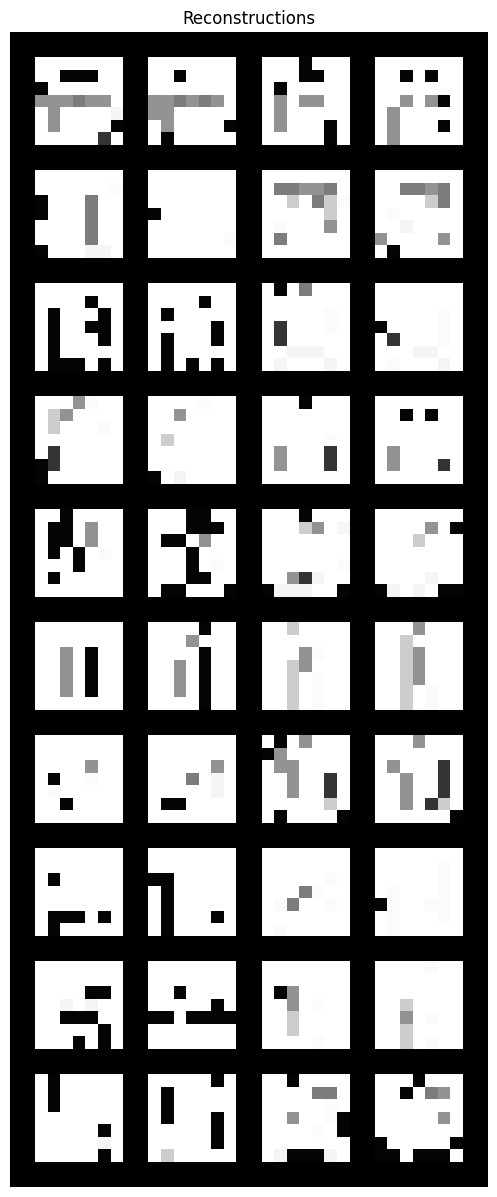

Epoch 65: 100%|██████████| 421/421 [00:14<00:00, 28.41it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


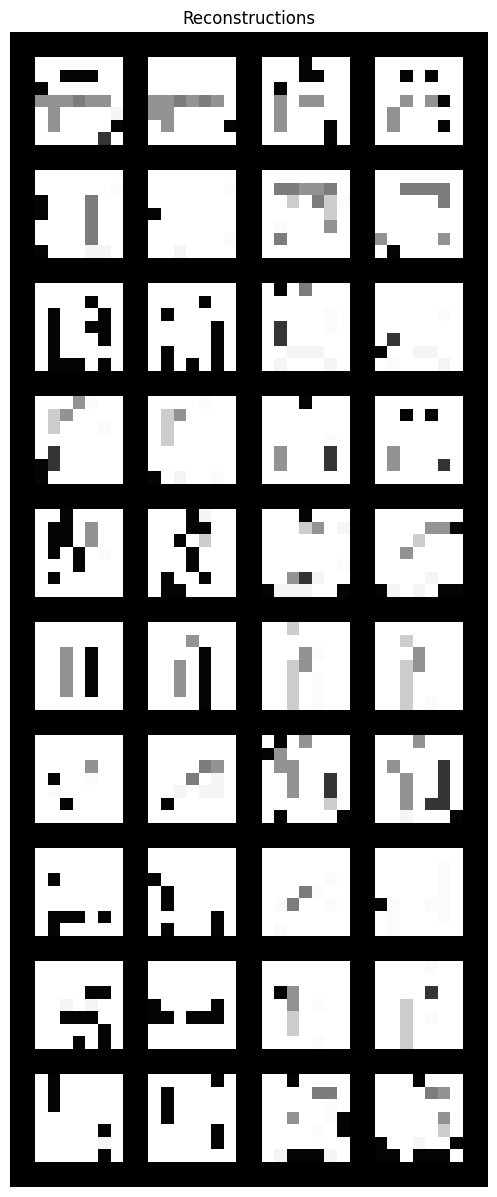

Epoch 66: 100%|██████████| 421/421 [00:14<00:00, 28.43it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


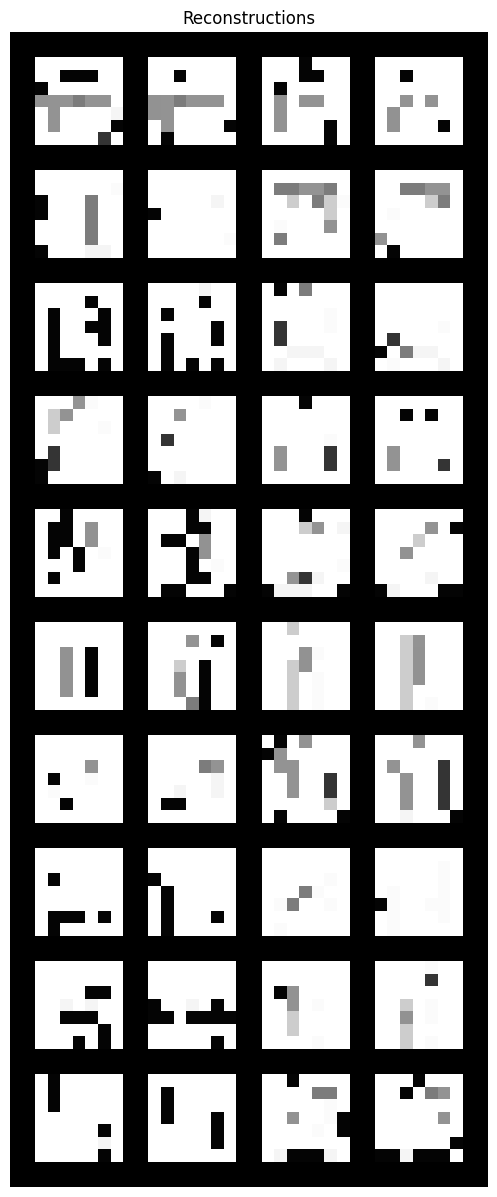

Epoch 67: 100%|██████████| 421/421 [00:15<00:00, 27.79it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


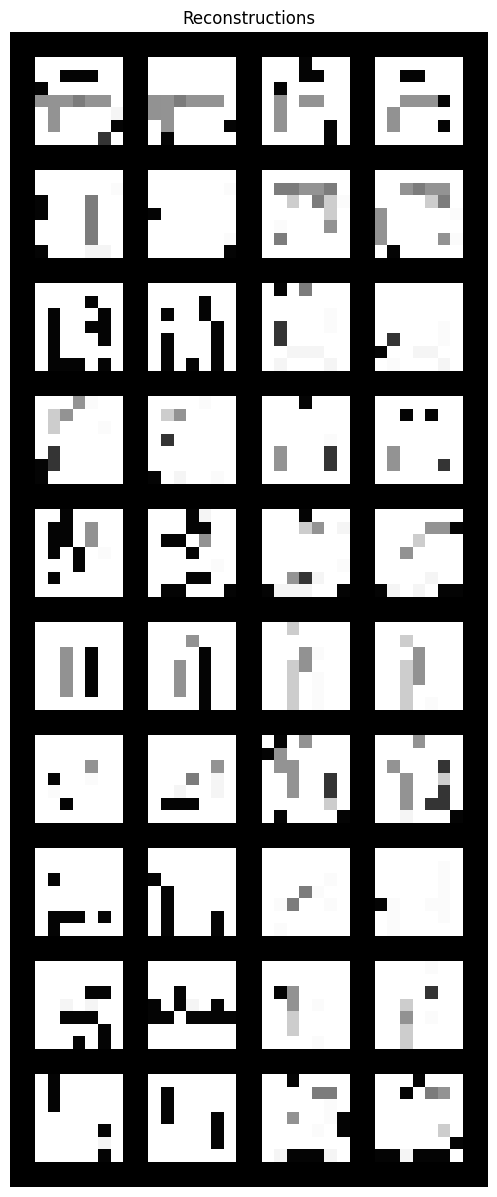

Epoch 68: 100%|██████████| 421/421 [00:15<00:00, 27.59it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


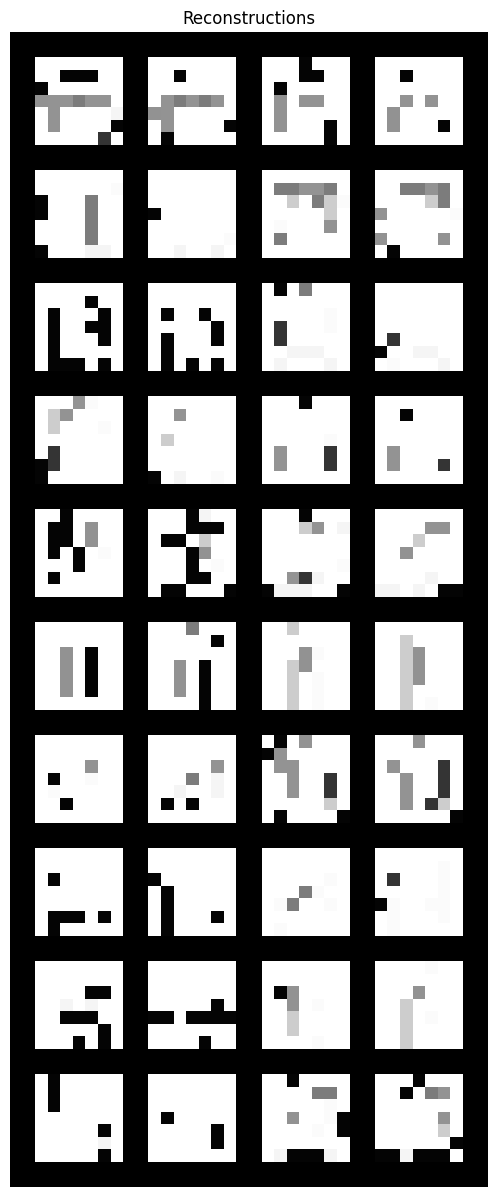

Epoch 69: 100%|██████████| 421/421 [00:15<00:00, 27.38it/s, v_num=0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.5607843].


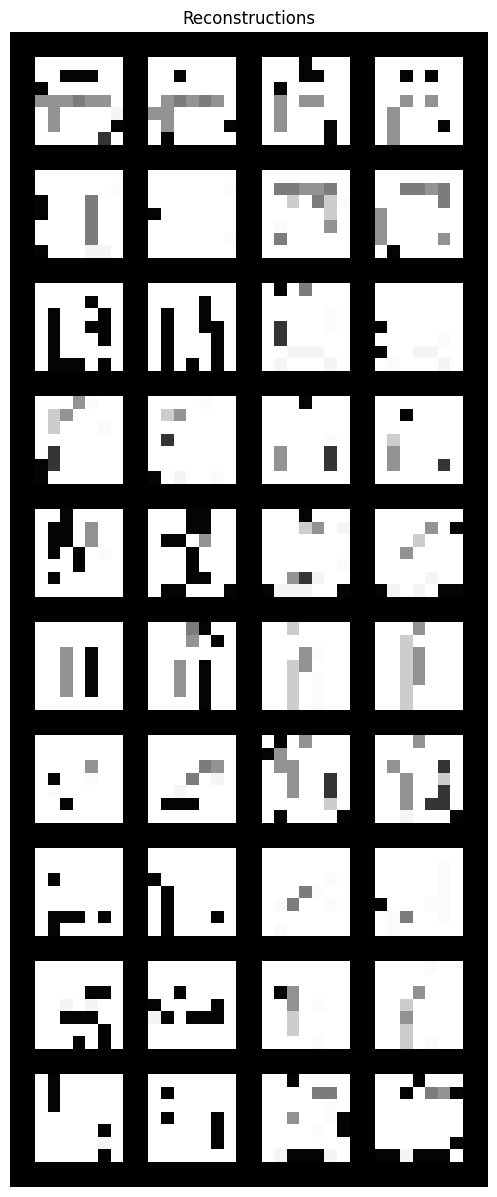

Epoch 69: 100%|██████████| 421/421 [00:16<00:00, 24.77it/s, v_num=0]

`Trainer.fit` stopped: `max_epochs=70` reached.


Epoch 69: 100%|██████████| 421/421 [00:16<00:00, 24.77it/s, v_num=0]


/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'test_dataloader' to speed up the dataloader worker initialization.


Testing DataLoader 0: 100%|██████████| 79/79 [00:01<00:00, 67.16it/s]


In [9]:
input_channels = 1  # only 1 chanel per token - token's id 
channels_hidden = 64    # for more complex datasets like cifar10 channels_dim=128 would be more appropriate (better results)
model_path = "../pretrained_models/pixel_cnn_on_tokens"
epochs = 70
num_classes = NUM_EMBEDDINGS

start = time.time()
model, result = train_pixel_cnn(epochs=epochs, dataloaders=tokenized_dataloaders, device=device, model_path=model_path, c_in=input_channels, c_hidden=channels_hidden, num_classes=num_classes)
end = time.time()

In [10]:
torch.save(model.state_dict(), f=os.path.join(model_path, "pixel_cnn.pth"))

In [11]:
training_time = (end - start) / 60
print(f"Training lasted for {training_time} minutes")

Training lasted for 19.321293584505717 minutes


Seed set to 1
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.1626422e-17..128.0].


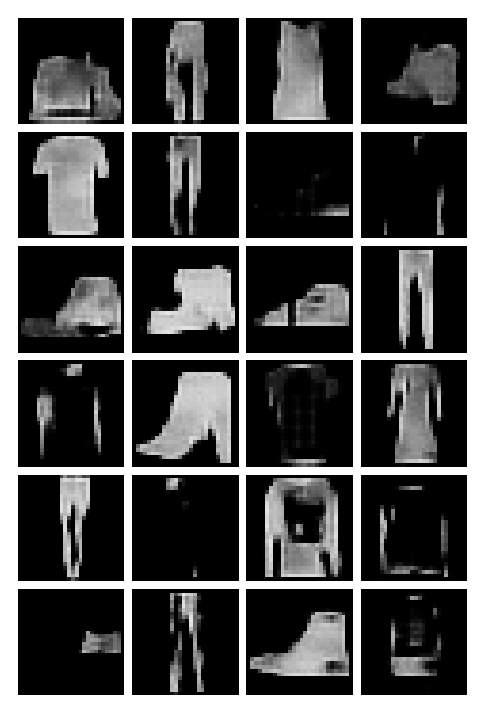

In [12]:
num_samples = 24
pl.seed_everything(1)

samples = model.sample(img_shape=(num_samples, input_channels, h, w))   # sample tokens of shape [B, Ch=1, H, W], here H=8, W=8
samples = samples.squeeze(1) # [B, Ch=1, H, W] --> [B, H, W]
samples = samples.to(device)

vq_vae.eval()
with torch.no_grad():
    b, h, w = samples.shape
    z_q = vq_vae.vq_layer.embedding(samples.long())
    z_q = z_q.permute(0, 3, 1, 2).contiguous()  # decoder // DeconvBlock takes [B, Ch, H, W]
    generated_images = vq_vae.normalize(vq_vae.decoder(z_q))

show_imgs(generated_images.cpu())